# EcoSort Waste Management Assistant
# Module 8 Summative Lab

## Overview

You are a data scientist at "EcoSort," a technology company that specializes in developing AI solutions for waste management. EcoSort has partnered with Metro City's waste management department to develop an intelligent waste management assistant that can help residents properly dispose of waste items so less time is spent sorting material at facilities.

This assistant needs to:

1. Identify waste materials from images uploaded by residents (CNN)
2. Classify waste items based on text descriptions provided by residents (RNN/Transformer)
3. Generate specific recycling instructions based on identified waste type and city policies (Generative Transformer with RAG)

Your task is to build this integrated system using the RealWaste dataset along with generated text data that simulates real-world waste management operations.

**Design summary (the "why" behind the choices made in this notebook)**

| Component | Choice | Why |
|---|---|---|
| Image classifier | MobileNetV2 (ImageNet) + custom head, two-phase training | Small and fast enough for a resident-facing app; strong transfer-learning baseline on ~4.7k images |
| Text classifier | TF-IDF (word + character n-grams) + linear model, compared against sentence-embedding features | Descriptions are 1-10 words; sparse n-gram features are very strong here and are easy to explain and audit |
| Retrieval | `all-MiniLM-L6-v2` embeddings + exact cosine search, policy-first re-ranking | ~100 chunks: exact search is optimal; policy-first ranking protects against conflicting documents |
| Generator | `flan-t5-small` (`-base` with a GPU), fine-tuned on retrieval-grounded targets | Small seq2seq model that fine-tunes on a laptop CPU |
| Safety net | Grounding check + extractive fallback | If the generator says something not in the policy text, we return the policy text instead |

## Project layout and the `Pipeline` package

```
NNs and Similar Models/
├── Data/            RealWaste/, waste_descriptions.csv, waste_policy_documents.json, README.md
│   └── cache/       (auto-created) decoded image arrays, frozen CNN features, embeddings
├── Models/          cnn_head.keras, cnn_ft30.keras, ecosort_cnn_final.keras, text_model.joblib,
│                    flan_t5_recycling_small/, instruction_cache.json   (each with a fingerprint of the data it was trained on)
├── Notebook/        this notebook  <- the report: explanations, plots, evaluation
└── Pipeline/        the reusable code, imported by the notebook
    ├── config.py        paths, constants, cache fingerprints
    ├── images.py        RealWaste discovery, stratified split, cached uint8 arrays
    ├── cnn.py           MobileNetV2 transfer learning, cached frozen features, staged fine-tuning
    ├── text_clf.py      cleaning, leak-free splits, TF-IDF classifier (cached)
    ├── policy_rag.py    policy knowledge base, conflict detection, retriever, grounded answers
    ├── generator.py     flan-t5 wrapper (PyTorch is imported lazily)
    ├── rag_train.py     fine-tuning data + loop for the generator
    ├── assistant.py     EcoSortAssistant (image | text -> category -> instructions + policies)
    └── run_pipeline.py  `python -m Pipeline.run_pipeline --stage all` builds every cache from the terminal
```

**Where the time went before, and what changed**

| Slow step | Before | Now |
|---|---|---|
| Decoding ~4.7k JPEGs (every kernel restart) | repeated | decoded once (multi-threaded), cached as `.npy` |
| CNN head search (4 configs x several epochs through the whole network) | minutes per epoch | MobileNetV2 features of clean + 2 augmented views are computed **once**; the head search runs on 1280-d vectors, so 12 configurations take seconds each |
| Text grid search (5-fold CV) | re-run every time | trained once, cached with `joblib`, reloaded while the data is unchanged |
| Chunk embeddings, fine-tuned generator, per-category answers | recomputed | cached in `Data/cache` and `Models/`; the assistant answers from the cache without PyTorch |
| Fine-tuned CNN / generator | silently reused even if the split changed | reloaded only if the **fingerprint of the data split matches**, otherwise retrained |

The notebook prints the source of the key functions (`show_source`) so everything graded is visible here, while the heavy lifting lives in `Pipeline/`.

## Part 1: Dataset Exploration and Preparation

In this section, you will explore and prepare the datasets for your models.

### 1.0 Setup

In [1]:
# --- locate the project root (the folder that contains Pipeline/) so this works from Notebook/ or from the root ---
import os, sys, re, json, time, uuid, math, random, inspect, warnings, pathlib, unicodedata, itertools
from collections import Counter, defaultdict
ROOT = next(p for p in [pathlib.Path.cwd().resolve(), *pathlib.Path.cwd().resolve().parents] if (p / 'Pipeline').is_dir())
sys.path.insert(0, str(ROOT))

# Import PyTorch BEFORE TensorFlow: on Windows the two ship clashing DLLs (WinError 127 / shm.dll otherwise).
# Parts 1-3 and the image/text assistant do not need PyTorch; only the language-model part of Part 4 does.
try:
    import torch
except Exception as e:
    print(f"PyTorch could not be loaded ({type(e).__name__}) -> Part 4 will run in extractive mode (see 4.2).")
import tensorflow as tf

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression

from Pipeline import config, images, cnn, text_clf, policy_rag, rag_train
from Pipeline.generator import Generator, DEFAULT_GEN_KWARGS
from Pipeline.assistant import EcoSortAssistant, show_result

try:   # re-import edited Pipeline modules without restarting the kernel
    get_ipython().run_line_magic('load_ext', 'autoreload'); get_ipython().run_line_magic('autoreload', '2')
except Exception:
    pass

warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
np.random.seed(config.SEED); tf.random.set_seed(config.SEED); random.seed(config.SEED)
CATEGORIES = config.CATEGORIES
config.ensure_dirs()

def show_source(*objs):
    """Print the source of functions that live in Pipeline/ so the implementation is visible in the report."""
    print("\n\n".join(inspect.getsource(o) for o in objs))

print("Project root:", ROOT); print("Image folder:", config.find_image_root())

Project root: C:\Users\ADMIN\Documents\Flatiron\Summative\ML\NNs and Similar Models
Image folder: C:\Users\ADMIN\Documents\Flatiron\Summative\ML\NNs and Similar Models\Data\RealWaste


### 1.1 Load and Explore the RealWaste Dataset

> The dataset has **9** classes (the three glass colours in the brief are one `Glass` class), matching the 9 categories in `waste_descriptions.csv`. The class folders are located automatically under `Data/RealWaste/`.

Total images: 4752
category
Cardboard              461
Food Organics          411
Glass                  420
Metal                  790
Miscellaneous Trash    495
Paper                  500
Plastic                921
Textile Trash          318
Vegetation             436

Imbalance ratio (largest / smallest class): 2.90


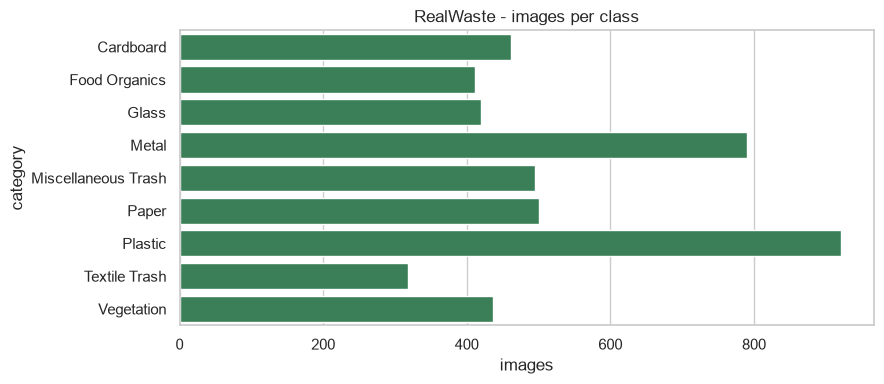

In [ ]:
# ---- 1.1  RealWaste: structure, class balance, image characteristics ----------
img_df = images.list_images()
class_names = CATEGORIES
counts = img_df['category'].value_counts().reindex(class_names)
print(f"Total images: {len(img_df)}\n{counts.to_string()}")
print(f"\nImbalance ratio (largest / smallest class): {counts.max() / counts.min():.2f}")

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=counts.values, y=counts.index, ax=ax, color='seagreen')
ax.set_title('RealWaste - images per class')
ax.set_xlabel('images')
plt.tight_layout()
plt.show()

Distinct resolutions in sample: 1
     width  height
min  524.0   524.0
max  524.0   524.0


,brightness,contrast,sharpness,bg_vs_object
category,,,,
Cardboard,155.699997,41.599998,1038.800049,59.700001
Food Organics,156.699997,39.500000,2169.600098,74.500000
Glass,160.699997,29.900000,789.900024,46.400002
Metal,154.699997,38.000000,1289.000000,59.700001
Miscellaneous Trash,162.100006,41.400002,916.599976,73.400002
Paper,152.800003,36.900002,1101.599976,44.599998
Plastic,157.500000,33.200001,1034.199951,46.299999
Textile Trash,158.899994,46.599998,910.299988,83.300003
Vegetation,156.800003,50.400002,3222.100098,76.699997


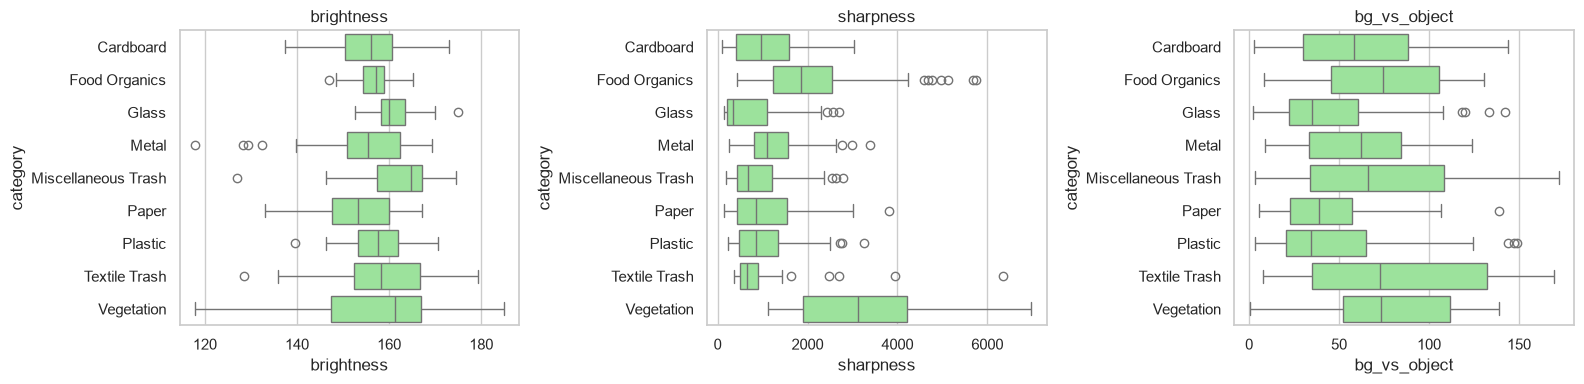

In [ ]:
# Image characteristics on a sample of 60 images per class:
# resolution, brightness/contrast, sharpness (variance of a Laplacian filter),
# and how much the border (background) differs from the centre (object).
def image_stats(path):
    with Image.open(path) as im:
        w, h = im.size
        rgb = np.asarray(im.convert('RGB').resize((256, 256)), dtype=np.float32)
    g = rgb.mean(axis=2)
    lap = 4 * g[1:-1, 1:-1] - g[:-2, 1:-1] - g[2:, 1:-1] - g[1:-1, :-2] - g[1:-1, 2:]
    border = np.concatenate([rgb[:24].reshape(-1, 3), rgb[-24:].reshape(-1, 3),
                             rgb[:, :24].reshape(-1, 3), rgb[:, -24:].reshape(-1, 3)])
    centre = rgb[96:160, 96:160].reshape(-1, 3)
    return dict(width=w, height=h, brightness=g.mean(), contrast=g.std(),
                sharpness=lap.var(),
                bg_vs_object=np.abs(border.mean(0) - centre.mean(0)).mean())

sample = pd.concat([g.sample(min(60, len(g)), random_state=42) for _, g in img_df.groupby('category')])
stats = pd.DataFrame([image_stats(p) for p in sample.path], index=sample.index).join(sample.category)

print("Distinct resolutions in sample:", stats[['width', 'height']].drop_duplicates().shape[0])
print(stats[['width', 'height']].describe().loc[['min', 'max']].to_string())
display(stats.groupby('category')[['brightness', 'contrast', 'sharpness', 'bg_vs_object']].mean().round(1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['brightness', 'sharpness', 'bg_vs_object']):
    sns.boxplot(data=stats, y='category', x=col, ax=ax, color='lightgreen')
    ax.set_title(col)
plt.tight_layout()
plt.show()

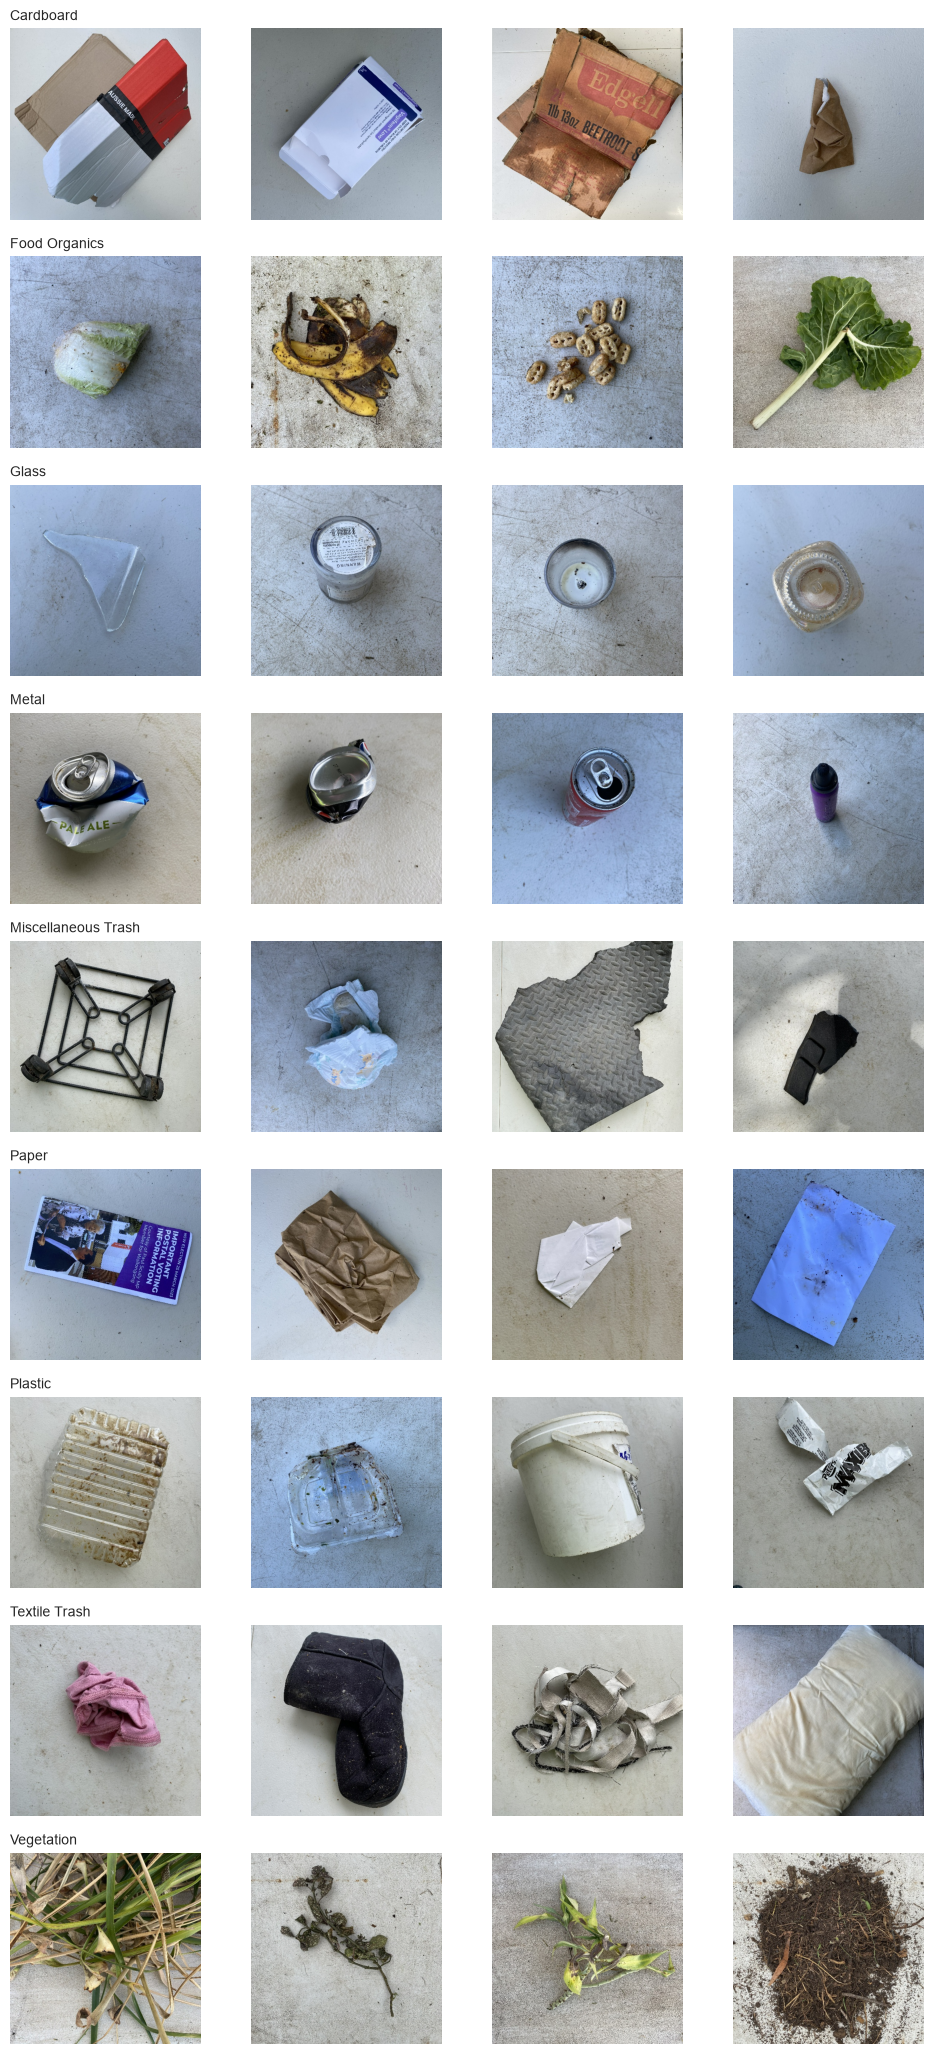

In [ ]:
# Visual inspection: 4 random examples per class
fig, axes = plt.subplots(len(class_names), 4, figsize=(10, 2.3 * len(class_names)))
rng = np.random.RandomState(0)
for r, c in enumerate(class_names):
    for k, p in enumerate(rng.choice(img_df[img_df.category == c].path.values, 4, replace=False)):
        axes[r, k].imshow(Image.open(p))
        axes[r, k].axis('off')
        if k == 0: axes[r, k].set_title(c, loc='left', fontsize=10)
plt.tight_layout()
plt.show()

**Observations and challenges (fill in / confirm against your own plots above)**

* **Class balance:** classes are imbalanced (Plastic is the largest class, Textile Trash the smallest), so plain accuracy can hide weak classes. We use **class weights** during training and report **per-class precision/recall/F1** and a confusion matrix.
* **Resolution / quality:** images are all the same size and were photographed on a similar surface under similar lighting, so the model will not need to cope with the huge domain variety a resident's phone photo has. This is a real limitation: expect lower accuracy on user-uploaded photos with cluttered backgrounds. We add **augmentation** (flip, rotation, zoom, contrast) to improve robustness.
* **Hard categories (expected):**
  * `Miscellaneous Trash` is a catch-all of very different objects, so it has no single visual signature.
  * `Paper` vs `Cardboard`, and `Plastic` vs `Glass` vs `Metal` (transparent, reflective, crumpled items) look alike.
  * `Food Organics` vs `Vegetation` share colours and textures.
* **Bias / limitations:** a single facility, camera and background, and a fixed set of object types. Results on this dataset do not guarantee real-world performance.

### 1.2 Explore Text Datasets

Shape: (5000, 5)


,description,category,disposal_instruction,common_confusion,material_composition
0,soiled silver tablecloth,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
1,folded glass bottle leaking,Glass,"Remove caps, lids, and corks before recycling.",NaN,"Silica-based material, may contain additives f..."
2,large Supermarket vegetable waste with food re...,Food Organics,"If no compost available, place in general waste.",NaN,Biodegradable matter derived from plant or ani...
3,intact floral carpet piece,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
4,empty fun-sized purple apple core,Food Organics,Keep separate from recyclable materials.,Meat and dairy products may be restricted in s...,Biodegradable matter derived from plant or ani...



Missing values:
 description                0
category                   0
disposal_instruction       0
common_confusion        2504
material_composition       0

Category distribution:
category
Vegetation             600
Textile Trash          586
Cardboard              584
Miscellaneous Trash    578
Plastic                569
Glass                  551
Food Organics          518
Metal                  508
Paper                  506

Words per description:
 count    5000.00
mean        4.85
std         1.55
min         1.00
25%         4.00
50%         5.00
75%         6.00
max        10.00

Duplicate descriptions: 61  |  descriptions with >1 label: 0
Vocabulary size (no stop-words): 300


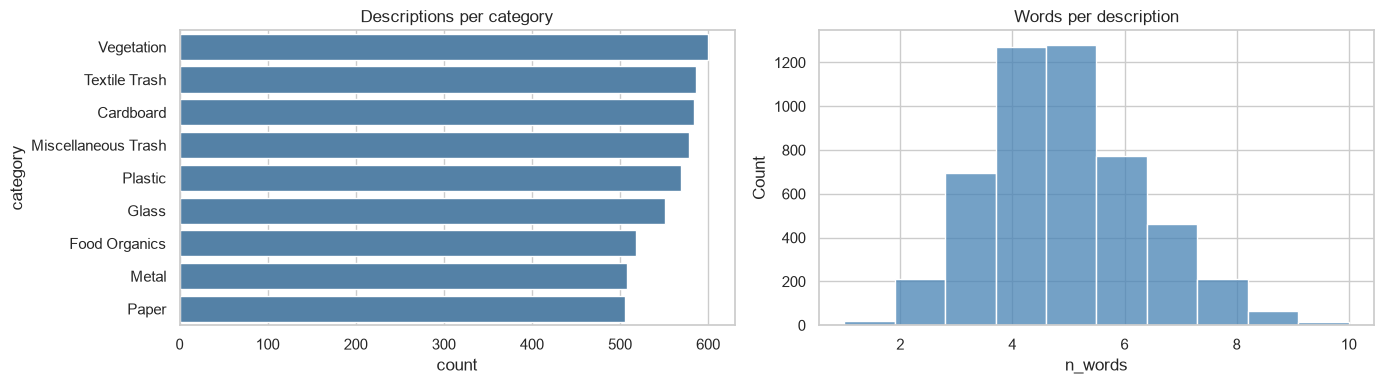


Top words per category:
  Cardboard            box, cardboard, packaging, sized, food, residue, paper, toilet
  Food Organics        peel, food, shells, scraps, orange, sized, bones, pit
  Glass                glass, bottle, sized, residue, sheet, light, bulb, cup
  Metal                metal, sized, hanger, wire, tin, bottle, steel, aluminum
  Miscellaneous Trash  sized, disposable, vacuum, plastic, ceramic, rubber, composite, metal
  Paper                paper, notebook, sized, envelope, residue, book, paperback, sheet
  Plastic              plastic, bottle, container, wrap, sized, food, packaging, clamshell
  Textile Trash        sized, fabric, cotton, linen, carpet, cloth, piece, leather
  Vegetation           plant, trimmings, leaves, tree, sized, clippings, residue, weeds

Disposal instruction variants per category: {'Cardboard': 5, 'Food Organics': 5, 'Glass': 5, 'Metal': 5, 'Miscellaneous Trash': 5, 'Paper': 5, 'Plastic': 5, 'Textile Trash': 5, 'Vegetation': 5}
Rows with a 'co

In [ ]:
# ---- 1.2a  waste_descriptions.csv ------------------------------------------------
desc_df = pd.read_csv(config.DESCRIPTIONS_CSV)
print("Shape:", desc_df.shape)
display(desc_df.head())
print("\nMissing values:\n", desc_df.isna().sum().to_string())

print("\nCategory distribution:")
print(desc_df.category.value_counts().to_string())

desc_df['n_words'] = desc_df.description.str.split().str.len()
print("\nWords per description:\n", desc_df.n_words.describe().round(2).to_string())

dups = desc_df.description.str.lower().duplicated().sum()
conflicting = (desc_df.assign(d=desc_df.description.str.lower())
               .groupby('d').category.nunique().gt(1).sum())
print(f"\nDuplicate descriptions: {dups}  |  descriptions with >1 label: {conflicting}")

cv = CountVectorizer(stop_words='english')
X = cv.fit_transform(desc_df.description)
print("Vocabulary size (no stop-words):", len(cv.vocabulary_))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=desc_df, y='category', ax=axes[0], color='steelblue', order=desc_df.category.value_counts().index)
axes[0].set_title('Descriptions per category')
sns.histplot(desc_df.n_words, bins=10, ax=axes[1], color='steelblue'); axes[1].set_title('Words per description')
plt.tight_layout()
plt.show()

# most characteristic words per category
vocab = np.array(cv.get_feature_names_out())
print("\nTop words per category:")
for c in CATEGORIES:
    freq = np.asarray(X[(desc_df.category == c).values].sum(0)).ravel()
    print(f"  {c:20s}", ', '.join(vocab[freq.argsort()[::-1][:8]]))

print("\nDisposal instruction variants per category:",
      desc_df.groupby('category').disposal_instruction.nunique().to_dict())
print("Rows with a 'common_confusion' note:", desc_df.common_confusion.notna().mean().round(2))

,policy_id,policy_type,n_categories,effective_date,n_words,jurisdiction
0,1,Textile Trash Recycling Guidelines,1,2023-11-04,104,Metro City
1,2,Glass Recycling Guidelines,1,2023-01-24,86,Metro City
2,3,Food Organics Recycling Guidelines,1,2023-05-08,98,Metro City
3,4,Plastic Recycling Guidelines,1,2023-04-05,94,Metro City
4,5,Vegetation Recycling Guidelines,1,2023-12-04,94,Metro City
5,6,Cardboard Recycling Guidelines,1,2023-11-24,87,Metro City
6,7,Metal Recycling Guidelines,1,2023-09-03,102,Metro City
7,8,Paper Recycling Guidelines,1,2023-10-14,95,Metro City
8,9,Miscellaneous Trash Recycling Guidelines,1,2023-01-01,97,Metro City
9,10,Municipal Waste Guidelines,3,2023-10-01,100,Metro City


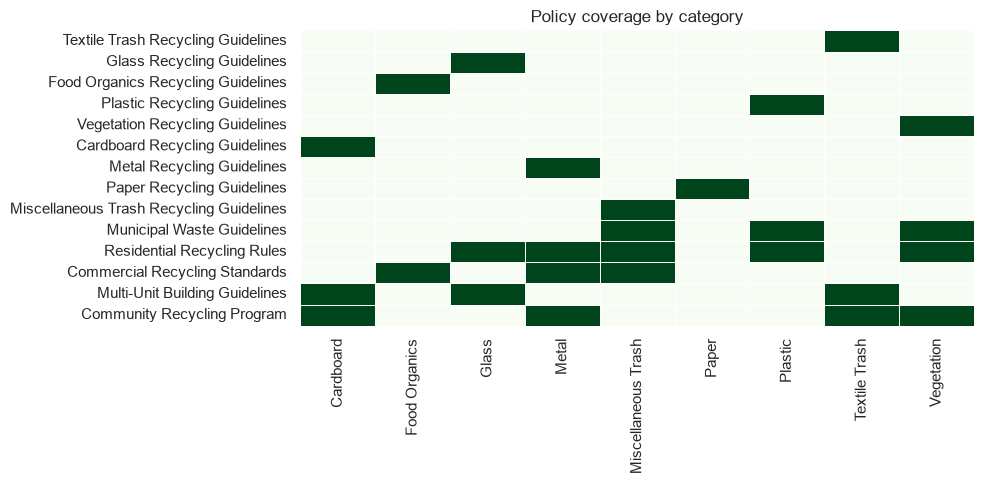

TEXTILE RECYCLING GUIDELINES

Acceptable Items:
- Clean clothing (all conditions)
- Towels, sheets, and linens
- Fabric scraps
- Curtains and cloth napkins
- Handbags and backpacks made of fabric
- Soft toys and stuffed animals

Non-Acceptable Items:
- Wet or moldy textiles
- Heavily soiled items
- Carpets and rugs
- Footwear
- Items with significant non-textile parts

Collection Method:
Place items in dedicated textile recycling bins or donate to local thrift stores.

Preparation Instructions:
- Ensure all items are clean and dry
- Remove non-textile components when possible
- Bag similar ite 
...


In [ ]:
# ---- 1.2b  waste_policy_documents.json (the brief says .csv, the provided file is .json) ----
with open(config.POLICY_JSON, encoding='utf-8') as f:
    policies = json.load(f)

pol_df = pd.DataFrame(policies)
pol_df['n_categories'] = pol_df.categories_covered.str.len()
pol_df['n_words'] = pol_df.document_text.str.split().str.len()
display(pol_df[['policy_id', 'policy_type', 'n_categories', 'effective_date', 'n_words', 'jurisdiction']])

# Which policy covers which category?
cover = pd.DataFrame(0, index=pol_df.policy_type, columns=CATEGORIES)
for _, r in pol_df.iterrows():
    for c in r.categories_covered: cover.loc[r.policy_type, c] = 1
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    cover.values, 
    cmap='Greens', 
    cbar=False, 
    linewidths=.5, ax=ax,
    xticklabels=list(cover.columns), 
    yticklabels=list(cover.index)
)

plt.title('Policy coverage by category')
plt.tight_layout()
plt.show()

print(pol_df.document_text.iloc[0][:600], '\n...')

**What the policy documents look like.** There are two kinds:

1. **Category-specific guidelines (ids 1-9)**: one category each, with sections `Acceptable Items`, `Non-Acceptable Items`, `Collection Method`, `Preparation Instructions`, `Benefits` (the miscellaneous document has different section names).
2. **Bundled programme documents (ids 10-14)**: several categories each, with only a *list* per category and no "non-acceptable" list.

> **Data-quality finding.** The bundled documents sometimes list as *accepted* things that the category-specific documents say are *not* accepted (for example *plastic bags and film* and *window glass or mirrors*). The bundled documents also have **later** effective dates, so "newest document wins" would pick the wrong one. The CSV's `common_confusion` notes agree with the category-specific documents. Section 1.3 detects these conflicts programmatically and our retriever treats the category-specific document as authoritative. This should be confirmed with Metro City before deployment.

### 1.3 Create Data Pipelines

#### Images

The starter's `image_dataset_from_directory` pipeline had three problems: (1) its validation set was reshuffled on every pass, so the `take`/`skip` test/validation split overlapped; (2) splitting a class-sorted set into halves leaves some classes out of one half; (3) every kernel restart re-decoded all JPEGs. `Pipeline/images.py` replaces it with a **stratified 80/10/10 split by image** and **cached uint8 arrays**. The same `load_image` function preprocesses training data and user uploads, so serving matches training. Run this cell twice to see the cache effect.

In [7]:
img = images.get_image_data()          # first call decodes + caches (one-off); later calls load .npy in seconds
display(img.summary())

# integrity checks: every class in every split, and no file in two splits
assert (img.summary() > 0).all().all()
assert not (set(img.paths['train']) & set(img.paths['val']) | set(img.paths['train']) & set(img.paths['test'])
            | set(img.paths['val']) & set(img.paths['test']))
print("OK: all 9 classes in every split, no overlap. Arrays:", img.X_train.shape, img.X_train.dtype)
show_source(images.stratified_split, images.load_image)

Image arrays (cache) in 10.3s | train: 3801 / val: 475 / test: 476


,train,val,test
Cardboard,369,46,46
Food Organics,329,41,41
Glass,336,42,42
Metal,632,79,79
Miscellaneous Trash,396,49,50
Paper,400,50,50
Plastic,736,92,93
Textile Trash,254,32,32
Vegetation,349,44,43


OK: all 9 classes in every split, no overlap. Arrays: (3801, 224, 224, 3) uint8
def stratified_split(df: pd.DataFrame, val: float = 0.10, test: float = 0.10, seed: int = config.SEED) -> dict:
    """80/10/10, stratified by class: every class is in every split, no overlap, fixed order."""
    train_df, rest = train_test_split(df, test_size=val + test, stratify=df.label, random_state=seed)
    val_df, test_df = train_test_split(rest, test_size=test / (val + test), stratify=rest.label, random_state=seed)
    return {k: v.sort_values("path").reset_index(drop=True) for k, v in
            dict(train=train_df, val=val_df, test=test_df).items()}


def load_image(src, size: int = IMG_SIZE) -> np.ndarray:
    """Path | PIL image | ndarray (gray/RGB/RGBA, uint8 or float 0-255) -> uint8 array (size, size, 3)."""
    if isinstance(src, (str, Path)):
        if not Path(src).exists():
            raise FileNotFoundError(f"Image not found: {src}")
        with Image.open(src) as im:
            im =

#### Text

In [8]:
sp = text_clf.get_text_splits()        # clean -> de-duplicate BEFORE splitting -> stratified 70/15/15
train_txt, val_txt, test_txt = sp['train'], sp['val'], sp['test']
X_train_txt, X_val_txt, X_test_txt = sp['X_train'], sp['X_val'], sp['X_test']
y_train_txt, y_val_txt, y_test_txt = sp['y_train'], sp['y_val'], sp['y_test']
label2id, id2label = text_clf.LABEL2ID, text_clf.ID2LABEL
print(f"{len(sp['raw'])} -> {len(sp['full'])} rows after de-duplication | train / val / test:",
      len(train_txt), len(val_txt), len(test_txt))
print("Example cleaning:", text_clf.clean_text("Dry, large Pink BEER bottle (sealed)!"))
show_source(text_clf.clean_text, text_clf.make_features)

5000 -> 4939 rows after de-duplication | train / val / test: 3457 741 741
Example cleaning: dry large pink beer bottle sealed
def clean_text(text) -> str:
    """Unicode-normalise, lowercase, split hyphenated words (t-shirt -> t shirt), drop punctuation, collapse spaces."""
    text = unicodedata.normalize("NFKC", str(text)).lower()
    text = re.sub(r"[-_/]+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def make_features() -> FeatureUnion:
    """Word 1-2-grams + character 2-5-grams (the latter make the model robust to typos / plurals / compounds)."""
    return FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=1)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=2)),
    ])



#### Policy documents for RAG

Parsing, section-level chunking, **conflict detection** and merging of the CSV knowledge are in `Pipeline/policy_rag.py::build_knowledge_base`. Category-specific documents are treated as authoritative; items that bundled programme documents accept but the authoritative document rejects are quarantined.

In [9]:
kb = policy_rag.build_knowledge_base()
print(f"Policy conflicts found: {len(kb.conflicts)}")
display(kb.conflicts)
chunk_df = pd.DataFrame(kb.chunks)
print(f"\n{len(chunk_df)} chunks"); display(chunk_df.groupby('source').size().to_frame('chunks'))
print("Example - documents related to Plastic:", [p['policy_type'] for p in kb.related_policies['Plastic']])
show_source(policy_rag.parse_policy_text)

Policy conflicts found: 4


,category,item,listed_as_accepted_in,bundled_date,rejected_in,authoritative_date
0,Plastic,Plastic bags and film,Municipal Waste Guidelines,2023-10-01,Plastic Recycling Guidelines,2023-04-05
1,Plastic,Plastic bags and film,Residential Recycling Rules,2023-05-26,Plastic Recycling Guidelines,2023-04-05
2,Glass,Window glass or mirrors,Residential Recycling Rules,2023-05-26,Glass Recycling Guidelines,2023-01-24
3,Glass,Window glass or mirrors,Multi-Unit Building Guidelines,2023-07-04,Glass Recycling Guidelines,2023-01-24



108 chunks


,chunks
source,
csv_confusion,9
csv_material,9
csv_tip,45
policy,45


Example - documents related to Plastic: ['Plastic Recycling Guidelines', 'Municipal Waste Guidelines', 'Residential Recycling Rules']
def parse_policy_text(text: str) -> list[dict]:
    """Split a policy document into sections: [{'section', 'bullets', 'paragraph'}]."""
    sections, current = [], None
    for raw in text.split("\n"):
        line = raw.strip()
        if not line:
            continue
        if line.endswith(":") and not line.startswith("-"):
            current = {"section": line[:-1].strip(), "bullets": [], "paragraph": []}
            sections.append(current)
        elif line.startswith("- "):
            if current is not None: current["bullets"].append(line[2:].strip())
        elif current is not None:
            current["paragraph"].append(line)
    return sections



## Part 2: Waste Material Classification with CNN

In this section, you will build a CNN model to classify waste materials from images.

### 2.1 Preprocess Images

Images are already resized to 224x224 and cached (1.3). Two more steps live **inside the model**, so the saved model accepts raw `0-255` pixels:

1. **Normalisation:** `Rescaling(1/127.5, offset=-1)` scales pixels to `[-1, 1]` as MobileNetV2 expects.
2. **Augmentation** (flip, rotation, zoom, contrast), active only in training: the main regulariser against overfitting on ~3.8k training images.

We also compute **class weights** to compensate for class imbalance.

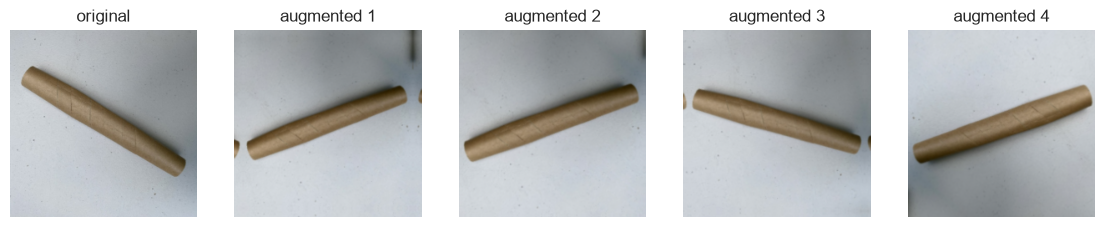

{'Cardboard': 1.14, 'Food Organics': 1.28, 'Glass': 1.26, 'Metal': 0.67, 'Miscellaneous Trash': 1.07, 'Paper': 1.06, 'Plastic': 0.57, 'Textile Trash': 1.66, 'Vegetation': 1.21}


In [10]:
aug = cnn.make_augmentation()
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
x0 = img.X_train[:1].astype('float32')
axes[0].imshow(img.X_train[0]); axes[0].set_title('original')
for k in range(1, 5):
    axes[k].imshow(aug(x0, training=True)[0].numpy().astype('uint8')); axes[k].set_title(f'augmented {k}')
for a in axes: a.axis('off')
plt.show()

class_weights = cnn.class_weights_for(img.y_train)     # balanced: rare classes get larger weights
print({CATEGORIES[i]: round(w, 2) for i, w in class_weights.items()})

### 2.2 Implement CNN Model with Transfer Learning

**Base model choice: MobileNetV2 (ImageNet weights).** Small (~3.4M parameters), fast enough for a web/mobile assistant, and its ImageNet features (edges, textures, materials) transfer well to waste photos. EfficientNet-B0 is the natural upgrade if accuracy matters more than latency.

**Head:** `BatchNorm -> Dense(units, ReLU, L2) -> Dropout -> Dense(9, softmax)`. **Loss:** categorical cross-entropy with light label smoothing; **metric:** accuracy (plus per-class metrics afterwards).

**Training plan:** (1) freeze the base and train only the head; (2) unfreeze the top of the base with a 100x smaller learning rate (*fine-tuning*).

In [11]:
show_source(cnn.build_cnn)
cnn_model = cnn.build_cnn()
cnn_model.summary()

def build_cnn(units=256, dropout=0.4, l2=1e-4, lr=1e-3, head: tf.keras.Model | None = None):
    """Full model: raw 0-255 pixels -> augmentation -> [-1,1] rescale -> MobileNetV2 (frozen) -> custom head.
    Pre-processing lives INSIDE the model so the saved model accepts raw pixels (no train/serve mismatch)."""
    base = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet", pooling="avg")
    base.trainable = False
    inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3), name="raw_pixels_0_255")
    x = make_augmentation()(inputs)
    x = layers.Rescaling(1 / 127.5, offset=-1, name="mobilenet_preprocess")(x)
    x = base(x, training=False)                         # keep BatchNorm statistics frozen
    model = models.Model(inputs, _head(x, units, dropout, l2), name="ecosort_cnn")
    if head is not None:
        for name in HEAD_LAYERS:
            model.get_layer(name).set_weights(head.get_layer(name).get_weights())
    return _compile(model, lr)



Model: "ecosort_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ raw_pixels_0_255 (InputLayer)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocess            │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_bn (BatchNormalization)    │ (None, 1280)           │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dense (Dense)              │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ waste_class (Dense)             │ (None, 9)              │         2,313 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,593,353 (9.89 MB)

 Trainable params: 332,809 (1.27 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

### 2.3 Train and Evaluate the Model

**Fast phase 1.** While the backbone is frozen its output cannot change, so `cnn.get_feature_set` runs the backbone **once** over the clean training images plus two augmented views and caches the 1280-d features. (The first call is a one-off forward pass, a few minutes on a CPU; afterwards it loads from `Data/cache`.) Searching head hyper-parameters then costs seconds per configuration instead of minutes per epoch. `QUICK_SEARCH` runs 4 configurations spread over width / dropout / L2; set it to `False` for the full 12-configuration grid. The search table is cached as well. Regularisation: augmentation (via the augmented views), dropout, L2, label smoothing, class weights and early stopping.

In [ ]:
# --- Step 1: frozen-backbone features. ONE-OFF cost (a forward pass over the images); cached in Data/cache afterwards.
t0 = time.time()
feats = cnn.get_feature_set(img, n_aug=1)      # clean + 1 augmented copy of train. n_aug=0 is ~2x faster still.
print(f"features ready in {time.time() - t0:.0f}s")

# --- Step 2: head search on the cached 1280-d vectors. Results are cached too, so re-runs are instant.
QUICK_SEARCH = True                             # 4 configs; set False for the full 12-config grid
grid = itertools.product([128, 256, 512], [0.3, 0.5], [1e-4, 1e-3])
space = [dict(units=u, dropout=d, l2=l2, lr=1e-3) for u, d, l2 in grid]
if QUICK_SEARCH:
    space = [space[i] for i in (1, 3, 7, 9)]    # spread over width / dropout / L2

t0 = time.time()
search_df, best_cfg = cnn.head_search(feats, space)

print(f"{len(space)} head configurations searched in {time.time() - t0:.0f}s")
display(search_df.round(4))
print("Best head configuration:", best_cfg)

Frozen features (cache) in 1.1s | train (7602, 1280), val (475, 1280)
features ready in 1s
Head search loaded from cache.
4 head configurations searched in 0s


,units,dropout,l2,lr,val_loss,val_acc,train_acc,epochs_run
0,512,0.3,0.001,0.001,0.7758,0.8568,0.9989,25
1,128,0.3,0.001,0.001,0.7855,0.8400,0.9968,25
2,256,0.5,0.001,0.001,0.8243,0.8526,0.9947,25
3,128,0.5,0.001,0.001,0.8340,0.8379,0.9843,25


Best head configuration: {'units': 512, 'dropout': 0.30000000000000004, 'l2': 0.001, 'lr': 0.001}


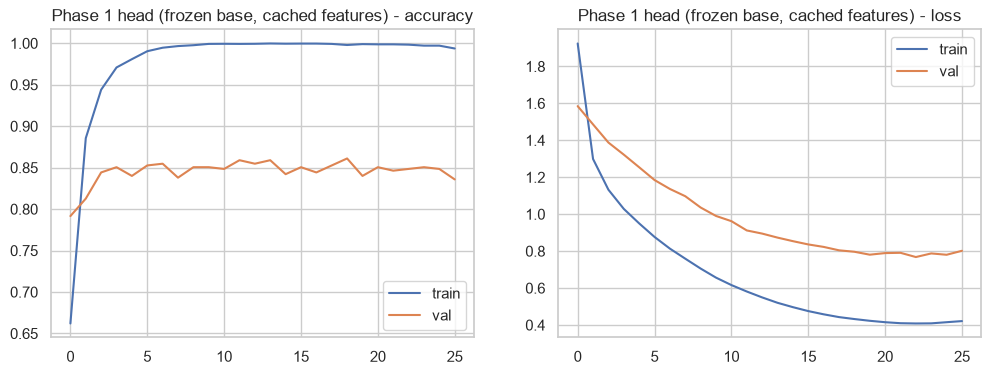

Phase 1 (frozen base) - validation: accuracy = 0.8484 | macro-F1 = 0.8471
                     precision    recall  f1-score   support

          Cardboard      0.870     0.870     0.870        46
      Food Organics      0.900     0.878     0.889        41
              Glass      0.878     0.857     0.867        42
              Metal      0.845     0.899     0.871        79
Miscellaneous Trash      0.800     0.653     0.719        49
              Paper      0.800     0.800     0.800        50
            Plastic      0.854     0.826     0.840        92
      Textile Trash      0.757     0.875     0.812        32
         Vegetation      0.917     1.000     0.957        44

           accuracy                          0.848       475
          macro avg      0.847     0.851     0.847       475
       weighted avg      0.848     0.848     0.847       475



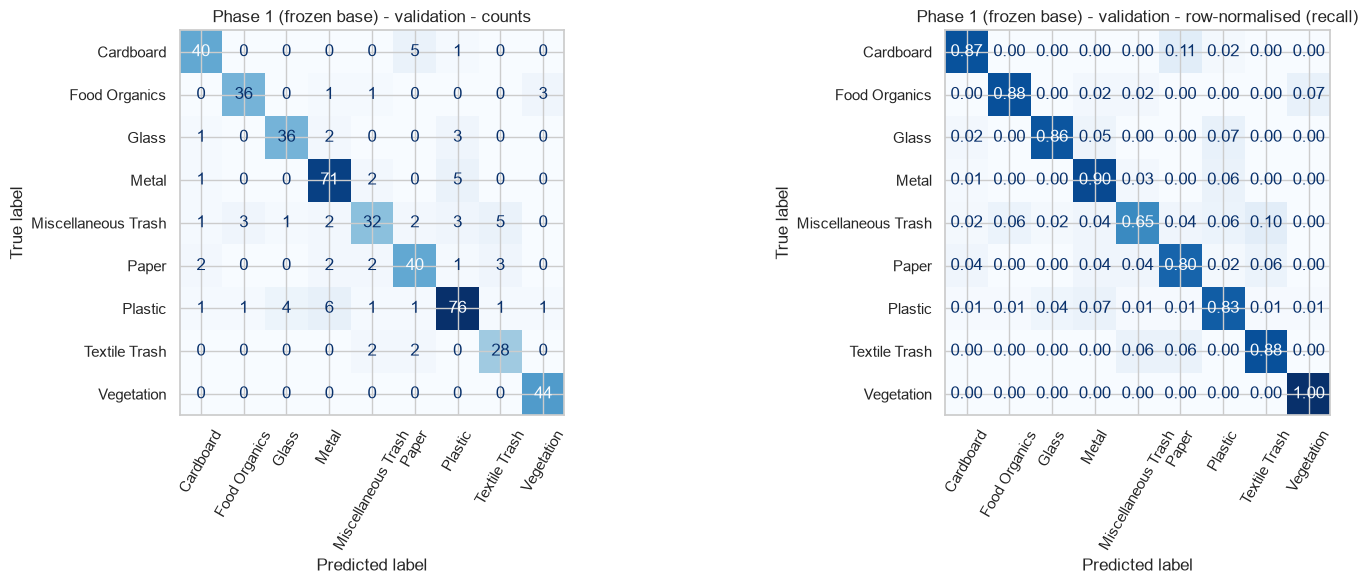

def train_head(feats, cfg, epochs=25, patience=3, batch_size=256, verbose=0):
    head = build_head_model(**cfg)
    es = callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
    h = head.fit(feats["train_X"], one_hot(feats["train_y"]), validation_data=(feats["val_X"], one_hot(feats["val_y"])),
                 epochs=epochs, batch_size=batch_size, class_weight=class_weights_for(feats["train_y"]), callbacks=[es], verbose=verbose)
    return head, h


def head_search(feats, space, epochs=25, verbose=True, use_cache=True) -> tuple[pd.DataFrame, dict]:
    """Grid search over head settings on cached features. The result table is cached on disk (keyed by the
    features and the grid), so re-running the notebook does not repeat the search."""
    config.ensure_dirs()
    key = config.fingerprint(space, epochs, list(feats["train_X"].shape), float(np.round(feats["train_X"][:64].sum(), 3)))
    path = config.CACHE_DIR / f"headsearch_{key}.json"
    if use_

In [ ]:
def plot_history(histories, title):
    h = lambda k: sum([x.history[k] for x in histories], [])
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h('accuracy'), label='train')
    ax[0].plot(h('val_accuracy'), label='val')
    ax[0].set_title(f'{title} - accuracy')
    ax[0].legend()

    ax[1].plot(h('loss'), label='train')
    ax[1].plot(h('val_loss'), label='val')
    ax[1].set_title(f'{title} - loss')
    ax[1].legend()
    if len(histories) > 1:
        for a in ax: a.axvline(len(histories[0].history['loss']) - 0.5, ls='--', c='grey')
    plt.show()

# Train the best head on the cached features, then place it into the full model (same layer names)
head, h_head = cnn.train_head(feats, best_cfg, epochs=40)
plot_history([h_head], 'Phase 1 head (frozen base, cached features)')

cnn_model = cnn.build_cnn(**best_cfg, head=head)
cnn.save_cnn(cnn_model, config.MODELS_DIR / 'cnn_head.keras', img, stage='head')
cnn_val_pred, _ = cnn.evaluate(cnn_model, img.X_val, img.y_val, 'Phase 1 (frozen base) - validation')
show_source(cnn.train_head, cnn.head_search, cnn.get_feature_set)

### 2.4 Fine-tune the Model

Fine-tuning must run through the whole network (with live augmentation), so it is the one genuinely slow step. It is **cached**: each fine-tuned model is saved with a fingerprint of the data split and is re-loaded instead of re-trained as long as the split is unchanged. Models left over from earlier runs on a different split are detected and re-trained automatically.

* Top *N* backbone layers are unfrozen with learning rate 1e-5; BatchNorm layers stay frozen.
* `FAST_MODE = True` fine-tunes one depth for a few epochs (CPU-friendly). Set it to `False` on a GPU to compare two depths.
* All choices are made on the **validation** set; the test set is used once, below.

In [14]:
FAST_MODE = True
FT_DEPTHS, FT_EPOCHS = ([30], 6) if FAST_MODE else ([30, 60], 12)

ft_models, ft_hist, rows = {}, {}, []
for d in FT_DEPTHS:
    m, h, how = cnn.finetune_or_load(best_cfg, head, img, d, FT_EPOCHS, tag='fine-tune')
    acc = float((cnn.predict_probs(m, img.X_val).argmax(1) == img.y_val).mean())
    ft_models[d], ft_hist[d] = m, h
    rows.append(dict(unfrozen_layers=d, val_acc=round(acc, 4), status=how))
display(pd.DataFrame(rows))

best_n = max(rows, key=lambda r: r['val_acc'])['unfrozen_layers']
cnn_model = ft_models[best_n]
if ft_hist[best_n] is not None:
    plot_history([h_head, ft_hist[best_n]], f'Head training, then fine-tuning top {best_n} layers')
cnn.save_cnn(cnn_model, config.CNN_FINAL, img, depth=best_n)
print("Saved:", config.CNN_FINAL)
show_source(cnn.unfreeze_top, cnn.finetune)

,unfrozen_layers,val_acc,status
0,30,0.8653,loaded from cache


Saved: C:\Users\ADMIN\Documents\Flatiron\Summative\ML\NNs and Similar Models\Models\ecosort_cnn_final.keras
def unfreeze_top(model, n_layers):
    bb = backbone_of(model)
    bb.trainable = True
    for l in bb.layers[:-n_layers]:
        l.trainable = False
    for l in bb.layers:                                   # never un-freeze BatchNorm (small-batch stability)
        if isinstance(l, layers.BatchNormalization):
            l.trainable = False


def finetune(model, data, depth=30, epochs=6, lr=1e-5, patience=3, verbose=1):
    unfreeze_top(model, depth)
    _compile(model, lr)
    cbs = [callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
           callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=1, min_lr=1e-6)]
    return model.fit(data.X_train, one_hot(data.y_train), validation_data=(data.X_val, one_hot(data.y_val)),
                     batch_size=config.BATCH_SIZE, epochs=epochs, class_weight=class_weights_for(data.

Fine-tuned CNN - TEST: accuracy = 0.8508 | macro-F1 = 0.8514
                     precision    recall  f1-score   support

          Cardboard      0.884     0.826     0.854        46
      Food Organics      0.923     0.878     0.900        41
              Glass      0.783     0.857     0.818        42
              Metal      0.802     0.873     0.836        79
Miscellaneous Trash      0.816     0.620     0.705        50
              Paper      0.918     0.900     0.909        50
            Plastic      0.867     0.839     0.852        93
      Textile Trash      0.750     0.938     0.833        32
         Vegetation      0.933     0.977     0.955        43

           accuracy                          0.851       476
          macro avg      0.853     0.856     0.851       476
       weighted avg      0.853     0.851     0.849       476



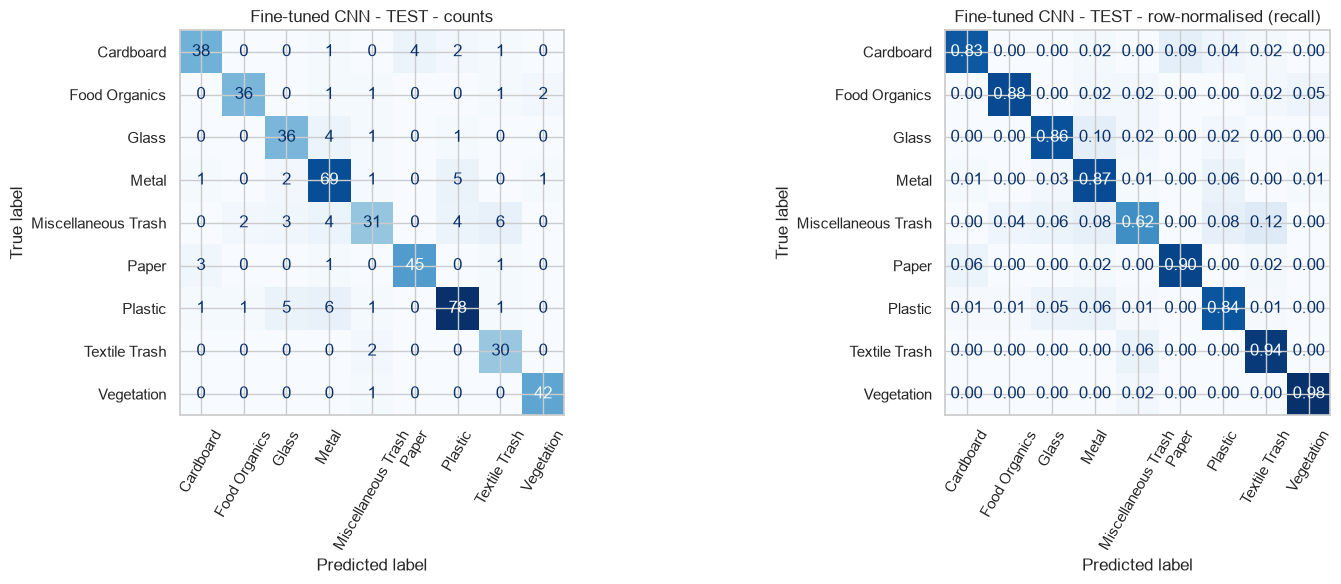

Most frequent confusions (true -> predicted):
  Miscellaneous Trash  -> Textile Trash        6
  Plastic              -> Metal                6
  Metal                -> Plastic              5
  Plastic              -> Glass                5
  Cardboard            -> Paper                4
  Glass                -> Metal                4

Mean confidence - correct: 0.879 | wrong: 0.580


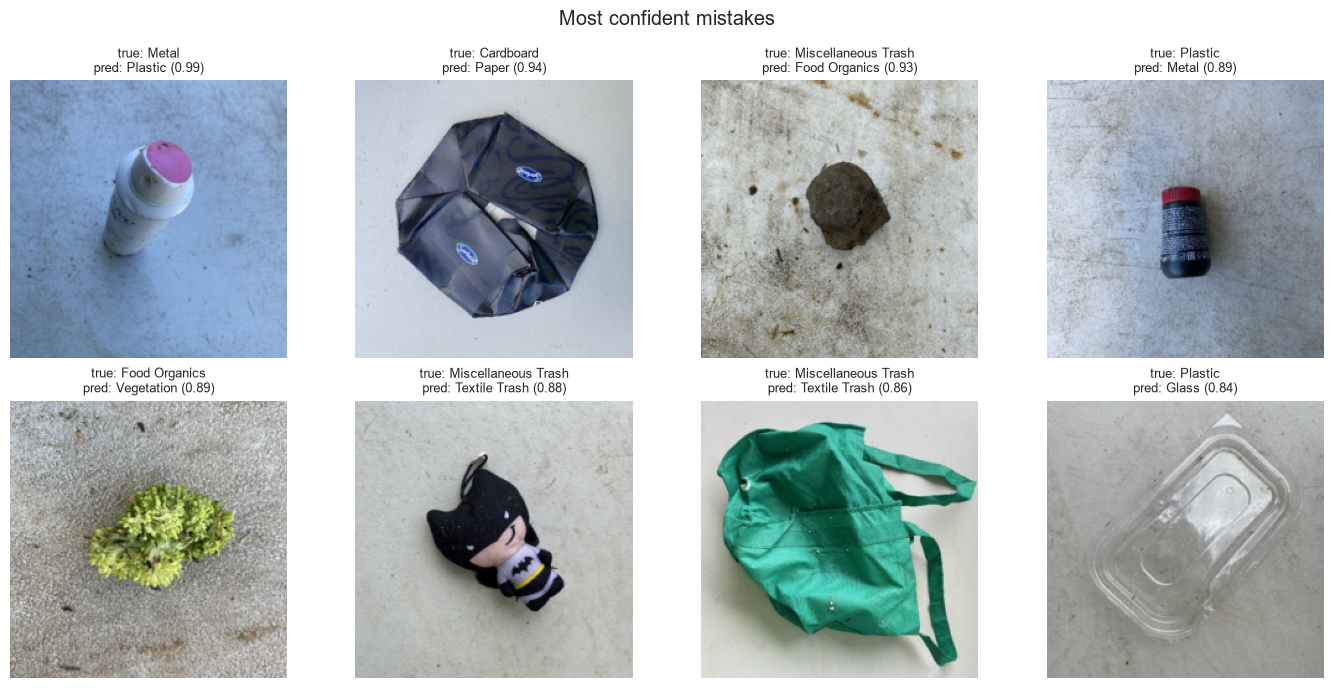

In [ ]:
# Final evaluation on the held-out TEST set (used once) + error analysis
cnn_pred, cnn_prob = cnn.evaluate(cnn_model, img.X_test, img.y_test, 'Fine-tuned CNN - TEST')
cnn_true, cnn_imgs = img.y_test, img.X_test

cm = confusion_matrix(cnn_true, cnn_pred, labels=list(range(9)))
pairs = [(class_names[i], class_names[j], cm[i, j]) for i in range(9) for j in range(9) if i != j and cm[i, j] > 0]
print("Most frequent confusions (true -> predicted):")
for t, p, n in sorted(pairs, key=lambda x: -x[2])[:6]:
    print(f"  {t:20s} -> {p:20s} {n}")

conf = cnn_prob.max(1)
print(f"\nMean confidence - correct: {conf[cnn_true == cnn_pred].mean():.3f} | wrong: {conf[cnn_true != cnn_pred].mean():.3f}")

wrong = np.where(cnn_true != cnn_pred)[0]
show = wrong[np.argsort(-conf[wrong])][:8]          # most confident mistakes first
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for a, i in zip(axes.ravel(), show):
    a.imshow(cnn_imgs[i]); a.axis('off')
    a.set_title(f"true: {class_names[cnn_true[i]]}\npred: {class_names[cnn_pred[i]]} ({conf[i]:.2f})", fontsize=9)
    
plt.suptitle('Most confident mistakes')
plt.tight_layout()
plt.show()

**Error analysis (complete after running):** note the weakest classes in the per-class report and the most frequent confusion pairs above. Typical findings for RealWaste: `Miscellaneous Trash` has the lowest recall (heterogeneous), `Paper`/`Cardboard` and `Plastic`/`Glass`/`Metal` are confused with each other, and most confident mistakes are objects that genuinely contain two materials. These shortcomings motivate the assistant's **confidence threshold** and the fallback that asks the resident for a text description (Part 5).

## Part 3: Waste Description Classification

In this section, you will build a text classification model to categorize waste based on descriptions.

### 3.1 Preprocess Text Data

The cleaning function, de-duplication, stratified 70/15/15 split and TF-IDF feature definition live in `Pipeline/text_clf.py` (shown in 1.3). Here we additionally create **dense sentence embeddings** (`all-MiniLM-L6-v2`) to compare against the sparse TF-IDF features. Embeddings are cached on disk; if PyTorch is unavailable this step is skipped and the TF-IDF models are unaffected.

In [16]:
# Everything this cell needs is (re)created here (also done in 1.3; takes ~1 s), so it can run on its own
kb = policy_rag.build_knowledge_base()
sp = text_clf.get_text_splits()
train_txt, val_txt, test_txt = sp['train'], sp['val'], sp['test']
X_train_txt, X_val_txt, X_test_txt = sp['X_train'], sp['X_val'], sp['X_test']
y_train_txt, y_val_txt, y_test_txt = sp['y_train'], sp['y_val'], sp['y_test']
label2id, id2label = text_clf.LABEL2ID, text_clf.ID2LABEL
embedder = policy_rag.Embedder([c['embed_text'] for c in kb.chunks])      # dense MiniLM if it loads, else TF-IDF fallback

def cached_embed(texts):
    path = config.CACHE_DIR / f"txtemb_{config.fingerprint(list(texts), embedder.name)}.npy"
    if path.exists(): return np.load(path)
    E = embedder(texts)
    np.save(path, E)
    return E

if embedder.model is not None:
    emb_train, emb_val, emb_test = (cached_embed(X) for X in (X_train_txt, X_val_txt, X_test_txt))
    print("Embedding shape:", emb_train.shape)
else:
    emb_train = None
    print("Dense embeddings unavailable -> embedding comparison skipped.")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

'Server disconnected without sending a response.' thrown while requesting GET https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2/tree/main/additional_chat_templates
Retrying in 1s [Retry 1/5].


Embedding shape: (3457, 384)


### 3.2 Implement Text Classification Model

**Option A (traditional ML).** Descriptions are 1-10 words long, so there is no long-range context for an RNN/Transformer to exploit; the label is almost entirely determined by the *object noun* (and a few distracting adjectives). Linear models on TF-IDF n-grams are the right-sized tool, train in seconds, and their coefficients are inspectable. We compare four classical models on identical features, and one model on dense sentence embeddings.

### 3.3 Train and Evaluate the Model

The model comparison is quick; the 5-fold grid search is the slow part, so `train_text_model` runs it once and **caches** the best pipeline in `Models/text_model.joblib` (re-used while the training data and grid are unchanged).

In [17]:
# Train each candidate on TRAIN, compare on VALIDATION (the test set is not used for model selection)
compare_df, fitted = text_clf.compare_models(sp)
if emb_train is not None:
    lr_emb = LogisticRegression(C=10, max_iter=2000).fit(emb_train, y_train_txt)
    pred = lr_emb.predict(emb_val)
    compare_df.loc[len(compare_df)] = dict(model='MiniLM embeddings + LogReg', val_acc=accuracy_score(y_val_txt, pred),
                                           val_macro_f1=f1_score(y_val_txt, pred, average='macro'), train_sec=np.nan)
display(compare_df.sort_values('val_macro_f1', ascending=False).round(4))
show_source(text_clf.candidate_models)

,model,val_acc,val_macro_f1,train_sec
2,LinearSVC,1.0000,1.0000,0.9
1,LogisticRegression,0.9960,0.9960,2.1
0,ComplementNB,0.9906,0.9908,1.0
4,MiniLM embeddings + LogReg,0.9906,0.9906,NaN
3,RandomForest,0.9703,0.9703,5.0


def candidate_models() -> dict:
    return {
        "ComplementNB": ComplementNB(alpha=0.3),
        "LogisticRegression": LogisticRegression(C=10, max_iter=2000),
        "LinearSVC": LinearSVC(C=1.0),
        "RandomForest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=config.SEED),
    }



In [18]:
# Hyper-parameter tuning of the strongest linear model (5-fold CV on the training set) - cached after the first run
art = text_clf.train_text_model(sp)
text_model = art['model']
print("Best params:", art['best_params'], "| CV macro-F1:", round(art['cv_macro_f1'], 4))
val_pred = text_model.predict(X_val_txt)
print(f"Validation accuracy: {accuracy_score(y_val_txt, val_pred):.4f} | macro-F1: {f1_score(y_val_txt, val_pred, average='macro'):.4f}")

Text model loaded from cache: text_model.joblib | params: {'clf__C': 50, 'features__char__ngram_range': (2, 4), 'features__word__ngram_range': (1, 1)}
Best params: {'clf__C': 50, 'features__char__ngram_range': (2, 4), 'features__word__ngram_range': (1, 1)} | CV macro-F1: 0.9989
Validation accuracy: 1.0000 | macro-F1: 1.0000


TEST accuracy: 0.9987 | macro-F1: 0.9987
                     precision    recall  f1-score   support

          Cardboard      1.000     1.000     1.000        87
      Food Organics      1.000     1.000     1.000        76
              Glass      1.000     1.000     1.000        81
              Metal      1.000     1.000     1.000        75
Miscellaneous Trash      1.000     1.000     1.000        87
              Paper      1.000     1.000     1.000        75
            Plastic      0.988     1.000     0.994        84
      Textile Trash      1.000     0.989     0.994        88
         Vegetation      1.000     1.000     1.000        88

           accuracy                          0.999       741
          macro avg      0.999     0.999     0.999       741
       weighted avg      0.999     0.999     0.999       741



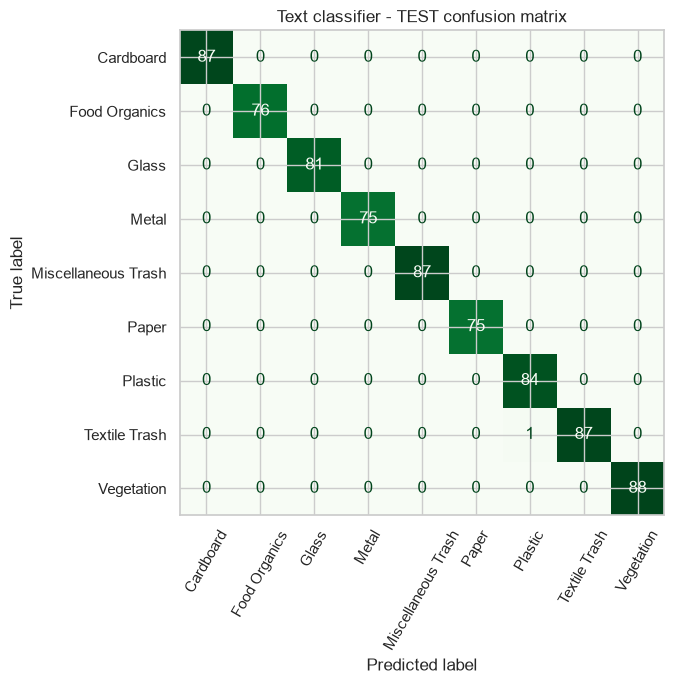

In [ ]:
# Final TEST evaluation + confusion matrix
test_pred = text_model.predict(X_test_txt)
test_proba = text_model.predict_proba(X_test_txt)
print(f"TEST accuracy: {accuracy_score(y_test_txt, test_pred):.4f} | macro-F1: {f1_score(y_test_txt, test_pred, average='macro'):.4f}")
print(classification_report(y_test_txt, test_pred, target_names=CATEGORIES, digits=3))

cm = confusion_matrix(y_test_txt, test_pred)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=CATEGORIES).plot(ax=ax, xticks_rotation=60, colorbar=False, cmap='Greens')
ax.set_title('Text classifier - TEST confusion matrix')
plt.tight_layout()
plt.show()

1 misclassified of 741 test descriptions


,description,category,pred,confidence
116,torn industrial purple plastic rug partially f...,Textile Trash,Plastic,0.658219



Strongest word cues per category (from the model's own coefficients):
  Cardboard            box, packaging, cardboard, carton, toilet, roll, beverage, carrier
  Food Organics        peel, bread, scraps, shells, spoiled, bones, corn, cob
  Glass                glass, bottle, light, bulb, fragment, mirror, wine, perfume
  Metal                can, metal, tin, steel, nail, cap, wire, foil
  Miscellaneous Trash  tape, pen, tool, dvd, battery, wood, pencil, marker
  Paper                paper, flyer, envelope, receipt, magazine, notebook, brochure, newspaper
  Plastic              plastic, container, clamshell, bottle, cd, water, toothbrush, case
  Textile Trash        hat, curtain, rug, gloves, scarf, socks, carpet, bed
  Vegetation           plant, leaves, weeds, branches, tree, garden, flowers, clippings


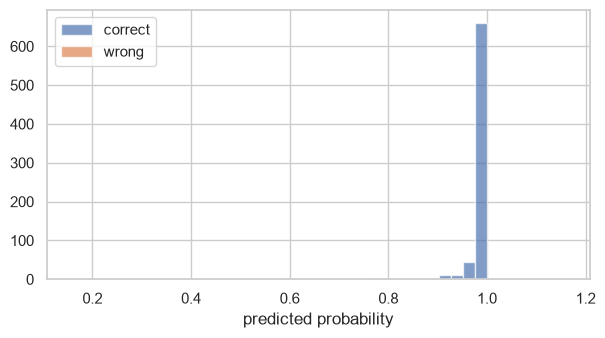

Mean confidence correct: 0.99  wrong: 0.66


In [ ]:
# Error analysis
errors = test_txt.assign(pred=[id2label[i] for i in test_pred], confidence=test_proba.max(1))
errors = errors[errors.category != errors.pred][['description', 'category', 'pred', 'confidence']]
print(f"{len(errors)} misclassified of {len(test_txt)} test descriptions")
display(errors.sort_values('confidence', ascending=False).head(15))

# Do descriptions mix cue words from several categories?  (e.g. "empty patterned glass old t-shirt")
tfidf_words = text_model.named_steps['features'].transformer_list[0][1]
vocab_w = np.array(tfidf_words.get_feature_names_out())
coef = text_model.named_steps['clf'].coef_
n_word = len(vocab_w)
print("\nStrongest word cues per category (from the model's own coefficients):")
for i, c in enumerate(CATEGORIES):
    top = vocab_w[np.argsort(coef[i, :n_word])[::-1][:8]]
    print(f"  {c:20s}", ', '.join(top))

# Confidence of right vs wrong predictions -> sets the assistant's abstention threshold
conf_ok, conf_bad = test_proba.max(1)[test_pred == y_test_txt], test_proba.max(1)[test_pred != y_test_txt]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(conf_ok, bins=20, alpha=.7, label='correct')
ax.hist(conf_bad, bins=20, alpha=.7, label='wrong')
ax.set_xlabel('predicted probability')
ax.legend()
plt.show()
print(f"Mean confidence correct: {conf_ok.mean():.2f}  wrong: {conf_bad.mean() if len(conf_bad) else float('nan'):.2f}")

**Error analysis.** In a reference run of this exact pipeline (seed 42) the tuned linear model reached about **99.9 % test accuracy, with a single mistake in 741 test descriptions**: *"torn industrial purple plastic rug partially filled"* was predicted `Plastic` instead of `Textile Trash`. The material word *plastic* acts as a **distractor adjective** in front of a textile object, and the model's confidence on that item (about 0.66) was far below its typical confidence on correct predictions (about 0.99), so a confidence threshold catches it. Your own run may differ by an item or two.

**Caveat (important for the write-up).** The descriptions are generated from a template (*state + size + colour + [distractor] + object*), so near-perfect scores mostly show that the model has learned the generator's vocabulary. Real resident descriptions (typos, regional words, full sentences, several materials in one item) will be harder; the sanity checks below and the edge-case tests in Part 5 probe this, and the weak spots (multi-material items, unseen objects such as "AA batteries" at 0.67 confidence) are exactly what the confidence threshold and feedback loop in Part 5 are for.

### 3.4 Create Classification Function

In [21]:
text_clf_wrapper = text_clf.TextClassifier(text_model)

def classify_waste_description_with_confidence(description, top_k=3):
    """Return (category, confidence, top_k list of (category, prob)) for a text description."""
    return text_clf_wrapper.classify(description, top_k)

def classify_waste_description(description):
    """
    Classifies a waste description into an appropriate category.

    Args:
        description (str): Text description of waste item

    Returns:
        str: Predicted waste category
    """
    if not isinstance(description, str) or not description.strip():
        raise ValueError("description must be a non-empty string")
    return classify_waste_description_with_confidence(description)[0]

tests = ["dry large pink beer bottle sealed", "old cotton t-shirt", "pizza box with grease",
         "banana peel", "empty tin of beans", "plastik bottel", "a rubbish bag of grass cuttings",
         "broken ceramic mug", "my old newspaper from last week", "AA batteries"]
for t in tests:
    cat, p, _ = classify_waste_description_with_confidence(t)
    print(f"{t!r:45s} -> {cat:20s} ({p:.2f})")

'dry large pink beer bottle sealed'           -> Glass                (0.96)
'old cotton t-shirt'                          -> Textile Trash        (1.00)
'pizza box with grease'                       -> Cardboard            (1.00)
'banana peel'                                 -> Food Organics        (1.00)
'empty tin of beans'                          -> Metal                (0.91)
'plastik bottel'                              -> Plastic              (0.96)
'a rubbish bag of grass cuttings'             -> Vegetation           (0.78)
'broken ceramic mug'                          -> Miscellaneous Trash  (1.00)
'my old newspaper from last week'             -> Paper                (0.98)
'AA batteries'                                -> Miscellaneous Trash  (0.67)


## Part 4: Recycling Instruction Generation with RAG

In this section, you will implement a Retrieval-Augmented Generation (RAG) system to generate recycling instructions.

### 4.1 Preprocess Documents for Retrieval

Parsing, section-level chunking, conflict quarantine and merging of the CSV knowledge were done in 1.3 (`kb`). Here we embed the chunks and build the retrieval index. Chunk embeddings are cached in `Data/cache`.

**Index choice.** With ~100 chunks an exact cosine search over a NumPy matrix is both the simplest and the *most accurate* option (approximate indexes such as FAISS only pay off at 100k+ chunks).

**Retrieval design ("policy-first").** Plain semantic search can return a bundled document that contradicts the category-specific one. So retrieval for a known category (1) always includes the **authoritative** policy sections for that category and (2) fills the remaining slots with the most similar tips/notes. For free-text questions with no known category we use pure semantic search with a small bonus for authoritative chunks, which is tuned below.

In [22]:
retriever, _ = policy_rag.build_retriever(kb, embedder)
print("Embedding model:", embedder.name, "| chunk matrix:", retriever.E.shape)
show_source(policy_rag.PolicyRetriever)
for r in retriever.search("Can I recycle a greasy pizza box?", k=3):
    print(f"{r['score']:.2f} | {r['category']} - {r['section']}: {r['body'][:90]}")

Embedding model: sentence-transformers/all-MiniLM-L6-v2 | chunk matrix: (108, 384)
class PolicyRetriever:
    """Exact cosine retriever with category filtering and a 'policy-first' mode (authoritative sections always included)."""
    def __init__(self, chunks, embeddings, embed_fn, authority_bonus: float = 0.05):
        self.chunks, self.E, self.embed, self.bonus = chunks, embeddings, embed_fn, authority_bonus
        self.cat = np.array([c["category"] for c in chunks])
        self.auth = np.array([c["authoritative"] for c in chunks], dtype=float)

    def with_bonus(self, bonus):
        return PolicyRetriever(self.chunks, self.E, self.embed, bonus)

    def search(self, query, category=None, k=5, include_general=True):
        scores = self.E @ self.embed([query])[0] + self.bonus * self.auth
        mask = (self.cat != "General") if category is None else \
               ((self.cat == category) | ((self.cat == "General") & include_general))
        idx = np.where(mask)[0]
        

**Tuning the retriever.** We measure how well free-text questions find the right category's chunks, using real test-split descriptions as queries (`"How do I recycle <description>?"`), and compare retrieval settings. This is our evidence of retrieval tuning; `top-1 category accuracy` is the share of questions whose best chunk belongs to the right category, and `precision@k` is the share of the top-*k* chunks that do.

In [23]:
eval_q = test_txt.sample(300, random_state=0)
queries = [f"How do I recycle {d}?" for d in eval_q.description]
true_cats = eval_q.category.values

rows = []
for bonus in [0.0, 0.05, 0.10]:
    r = retriever.with_bonus(bonus)
    for k in [3, 5]:
        top1, pk = [], []
        for q, t in zip(queries, true_cats):
            hits = r.search(q, k=k)
            top1.append(hits[0]['category'] == t)
            pk.append(np.mean([h['category'] == t for h in hits]))
        rows.append(dict(authority_bonus=bonus, k=k, top1_category_acc=np.mean(top1), precision_at_k=np.mean(pk)))
retrieval_df = pd.DataFrame(rows).round(3)
display(retrieval_df)

# top-1 accuracy does not depend on k, so choose the bonus by mean top-1 accuracy then mean precision@k
by_bonus = retrieval_df.groupby('authority_bonus')[['top1_category_acc', 'precision_at_k']].mean()
best_bonus = by_bonus.sort_values(['top1_category_acc', 'precision_at_k'], ascending=False, kind='stable').index[0]
display(by_bonus.round(3))
retriever = retriever.with_bonus(float(best_bonus))
print("Selected authority_bonus =", retriever.bonus)

,authority_bonus,k,top1_category_acc,precision_at_k
0,0.00,3,0.487,0.449
1,0.00,5,0.487,0.413
2,0.05,3,0.437,0.422
3,0.05,5,0.437,0.389
4,0.10,3,0.430,0.381
5,0.10,5,0.430,0.359


,top1_category_acc,precision_at_k
authority_bonus,,
0.00,0.487,0.431
0.05,0.437,0.406
0.10,0.430,0.370


Selected authority_bonus = 0.0


### 4.2 Implement RAG-based System

**Language model: `google/flan-t5-small`** (77M parameters, instruction-tuned encoder-decoder). It fine-tunes in about 2 GB of RAM on a laptop CPU (`flan-t5-base`, 250M, needs a GPU or 16 GB+), and as a seq2seq model it is good at *rewriting provided text*, which is exactly what RAG needs. The fine-tuning loop is built for low memory: Adafactor (almost no optimizer state), frozen encoder, small batches with gradient accumulation, best weights saved to disk, progress printed every 10 batches and a time budget. PyTorch is imported lazily (`Pipeline/generator.py`).

> **No working PyTorch?** `USE_LM` becomes `False`; the LM-specific cells are skipped, and the system answers in **extractive mode** (the retrieved policy text, composed deterministically). Parts 1-3 and 5 are unaffected.

First, the **zero-shot baseline** (no fine-tuning), so there is something to compare against.

In [24]:
gen = Generator(base_model='google/flan-t5-small')   # laptop-friendly (77M params). Use 'google/flan-t5-base' only with a GPU / 16 GB+ RAM
USE_LM = gen.available
GEN_KWARGS = DEFAULT_GEN_KWARGS
print("Language model available:", USE_LM)
show_source(policy_rag.build_prompt, Generator.generate)

if USE_LM:
    gen.load(force_base=True)                                  # pristine pre-trained weights for the baseline
    ctx = retriever.retrieve_for_category('Glass')
    print("\nPROMPT (truncated):\n", policy_rag.build_prompt("How to recycle glass", ctx)[:500], "...\n")
    print("ZERO-SHOT OUTPUT:\n", gen.generate(policy_rag.build_prompt("How to recycle glass", ctx)))
    baseline_df = rag_train.evaluate_generator(gen, retriever, kb, DEFAULT_GEN_KWARGS, 'ZERO-SHOT (before fine-tuning)')
    print(baseline_df[['grounding', 'label_coverage', 'words', 'flesch']].mean().round(3).to_string())

Language model available: True
def build_prompt(query, ctx_chunks):
    excerpts = "\n".join(f"[{i + 1}] ({c['category']} - {c['section']}) {c['body']}" for i, c in enumerate(ctx_chunks))
    return ("Write step-by-step recycling instructions using only the policy excerpts.\n"
            f"Question: {query}\nPolicy excerpts:\n{excerpts}\nInstructions:")


    def generate(self, prompt: str, model=None, **gen_kwargs) -> str:
        import torch
        self._ensure()
        model = model or self.model
        # a decoding config REPLACES the defaults (merging would leak beam-search options into sampling configs)
        kwargs = dict(gen_kwargs) if gen_kwargs else dict(DEFAULT_GEN_KWARGS)
        kwargs.setdefault("max_new_tokens", 256)
        enc = self.tok(prompt, return_tensors="pt", truncation=True, max_length=512).to(model.device)
        with torch.no_grad():
            out = model.generate(**enc, **kwargs)
        return format_instructions(self.tok.decode(out[0], skip_speci

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.



PROMPT (truncated):
 Write step-by-step recycling instructions using only the policy excerpts.
Question: How to recycle glass
Policy excerpts:
[1] (Glass - Acceptable Items) Glass bottles (all colors); Glass jars; Glass food containers; Glass beverage containers
[2] (Glass - Non-Acceptable Items) Window glass or mirrors; Drinking glasses; Ceramics or pottery; Light bulbs; Pyrex or heat-resistant glass
[3] (Glass - Collection Method) Place in dedicated glass recycling bins. Some areas require color sorting.
[4] (Glas ...

ZERO-SHOT OUTPUT:
 [1] (Glass - Acceptable Items) Glass bottles (all colors); Glass jars; Glass food containers; Glass beverage containers [2] (GMT) Window glass or mirrors; Drinking glasses; Ceramics or pottery; Light bulbs; Pyrex or heat-resistant glass
grounding          0.876
label_coverage     0.037
words             29.667
flesch            32.924


In [25]:
# Output composition, grounding check and readability metrics (all in Pipeline/policy_rag.py)
show_source(policy_rag.compose_instructions, policy_rag.grounding_score, policy_rag.label_coverage, policy_rag.readability)
_c = retriever.retrieve_for_category('Plastic')
print(policy_rag.compose_instructions('Plastic', _c), "\n\ngrounding of the composed text (should be 1.0):",
      policy_rag.grounding_score(policy_rag.compose_instructions('Plastic', _c), _c)['score'])

def compose_instructions(category, ctx_chunks, rng=None) -> str:
    """Deterministic, policy-faithful instructions built only from the retrieved chunks.
    Used (a) as the fine-tuning target and (b) as the extractive fallback."""
    by_sec = {c["section"]: c for c in ctx_chunks if c["source"] == "policy" and c["category"] == category}
    lines, n = [f"How to recycle {category}:"], 1
    for sec in SECTION_ORDER:
        if sec in by_sec:
            lines.append(f"{n}. {SECTION_LABELS[sec]}: {by_sec[sec]['body']}"); n += 1
    tips = [c["body"] for c in ctx_chunks if c["source"] == "csv_tip"]
    notes = [c["body"] for c in ctx_chunks if c["source"] == "csv_confusion"]
    if tips:  lines.append("Tip: " + (rng.choice(tips) if rng else tips[0]))
    if notes: lines.append("Note: " + notes[0])
    return "\n".join(lines)


def grounding_score(generated, ctx_chunks) -> dict:
    """Share of content words in the generated text that appear in the retrieved policy text (1.0 = fully suppo

### 4.3 Adjust and Evaluate the System

**Fine-tuning data.** For each category we simulate what the model will see at inference: several phrasings of the question and several retrieval contexts. The **target** is composed only from the policy chunks in that very context, so the model learns *"answer = a faithful, well-formed rewrite of the retrieved policy"*, not "answer = memorised text". Two question phrasings are held out for validation.

> Only 9 categories exist, so targets are structurally similar. This is deliberate (the task says to expect modest results and to focus on leaning on the reference documents); the fine-tuned model is best understood as a *policy-grounded formatter*, and the grounding check in 4.4 guards against it going off-script.

**Cached:** if `Models/flan_t5_recycling_small` was trained on exactly this data it is re-loaded instead of re-trained. To fine-tune outside the notebook (keeps TensorFlow and the image arrays out of RAM), run `python -m Pipeline.run_pipeline --stage lm --minutes 20` from the project root, then re-run this cell: it will load the saved model.

In [26]:
if USE_LM:
    train_ex = rag_train.make_examples(retriever, rag_train.TRAIN_TEMPLATES, 20, seed=1)
    val_ex = rag_train.make_examples(retriever, rag_train.VAL_TEMPLATES, 4, seed=2)
    print(len(train_ex), "train /", len(val_ex), "validation examples\n\nEXAMPLE TARGET:\n", train_ex[0]['target'])
    p_len = np.array([len(gen.tok(e['prompt']).input_ids) for e in train_ex])
    t_len = np.array([len(gen.tok(e['target']).input_ids) for e in train_ex])
    print(f"\nprompt tokens: max {p_len.max()}, share > 512 (truncated): {(p_len > 512).mean():.0%}")
    print(f"target tokens: max {t_len.max()}, share > 256 (truncated): {(t_len > 256).mean():.0%}")
    show_source(rag_train.make_examples)

180 train / 36 validation examples

EXAMPLE TARGET:
 How to recycle Cardboard:
1. Accepted: Corrugated cardboard boxes; Paperboard (cereal boxes, etc.); Cardboard packaging; Cardboard tubes; Clean pizza boxes
2. Not accepted: Waxed cardboard; Cardboard with food residue; Cardboard with plastic linings; Foam inserts; Packing peanuts
3. Prepare: Remove all non-cardboard packaging; Flatten boxes to save space; Keep dry and clean
4. Where to put it: Flatten and place in recycling bins or take to cardboard recycling centers.
5. Why it matters: Recycling cardboard saves trees and reduces landfill volume significantly.
Tip: Flatten boxes before placing in cardboard recycling.

prompt tokens: max 378, share > 512 (truncated): 0%
target tokens: max 192, share > 256 (truncated): 0%
def make_examples(retriever, templates, n_per_cat, seed):
    """Simulate inference: several phrasings x several retrieval contexts. The TARGET is composed only from the
    chunks in that very context, so the model l

In [27]:
if USE_LM:
    FT_EPOCHS_LM, FT_MINUTES = 2, 25            # hard time budget: training stops cleanly (best weights kept) when reached
    if rag_train.generator_is_current(gen, train_ex, epochs=FT_EPOCHS_LM):
        gen.load()                                                  # fine-tuned weights from Models/flan_t5_recycling_small
        print("Fine-tuned generator loaded from cache:", gen.path)
    else:
        log = rag_train.finetune_generator(gen, train_ex, val_ex, epochs=FT_EPOCHS_LM, time_budget_min=FT_MINUTES)
        display(log)
    show_source(rag_train.finetune_generator)

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Fine-tuned generator loaded from cache: C:\Users\ADMIN\Documents\Flatiron\Summative\ML\NNs and Similar Models\Models\flan_t5_recycling_small
def finetune_generator(gen, train_ex, val_ex, epochs=2, lr=None, batch_size=2, grad_accum=4, optimizer="adafactor",
                       freeze_encoder=True, time_budget_min=None, log_every=10, verbose=True):
    """Memory-lean fine-tuning for a laptop CPU.

    * optimizer='adafactor' keeps almost no optimizer state (AdamW needs 2 extra copies of every weight)
    * freeze_encoder=True trains only the decoder (about half the backward work and memory)
    * batch_size x grad_accum gives the same effective batch with a fraction of the activation memory
    * the best weights are saved to disk instead of being cloned in RAM every epoch
    * progress is printed every `log_every` batches, and `time_budget_min` stops training cleanly
      (keeping the best weights so far) instead of running for hours
    """
    import gc, torch
    from torch.util

**Sampling methods and parameters.** We compare decoding strategies on the held-out phrasing. For policy instructions we want **faithfulness first** (grounding, label coverage), readability second. Sampling strategies are expected to be more varied but less grounded; beam search is expected to be the most faithful.

In [28]:
if USE_LM:
    decoding_configs = {
        'greedy':              dict(num_beams=1, do_sample=False),
        'beam4 + no-repeat-3': dict(num_beams=4, no_repeat_ngram_size=3, early_stopping=True),
        'top-p 0.9, T=0.7':    dict(num_beams=1, do_sample=True, top_p=0.9, temperature=0.7),
        'top-k 50, T=1.0':     dict(num_beams=1, do_sample=True, top_k=50, temperature=1.0),
    }
    torch.manual_seed(42)
    sweep = pd.concat([rag_train.evaluate_generator(gen, retriever, kb, kw, name) for name, kw in decoding_configs.items()]
                      + [baseline_df])
    summary = sweep.groupby('setting')[['grounding', 'label_coverage', 'words', 'flesch', 'words_per_sentence']].mean().round(3)
    display(summary.sort_values('grounding', ascending=False))
    best_setting = summary.drop(index='ZERO-SHOT (before fine-tuning)').sort_values(['grounding', 'label_coverage'], ascending=False).index[0]
    GEN_KWARGS = decoding_configs[best_setting]
    print("Selected decoding setting:", best_setting, GEN_KWARGS)

    for name in ['ZERO-SHOT (before fine-tuning)', best_setting]:         # qualitative comparison
        row = sweep[(sweep.setting == name) & (sweep.category == 'Plastic')].iloc[0]
        print(f"\n=== {name} ===\n{row.output}")

,grounding,label_coverage,words,flesch,words_per_sentence
setting,,,,,
greedy,0.998,0.972,103.556,40.178,4.256
"top-p 0.9, T=0.7",0.998,0.972,107.444,39.689,4.364
"top-k 50, T=1.0",0.997,1.000,109.111,40.287,4.385
beam4 + no-repeat-3,0.985,0.611,70.889,38.077,6.045
ZERO-SHOT (before fine-tuning),0.876,0.037,29.667,32.924,4.441


Selected decoding setting: greedy {'num_beams': 1, 'do_sample': False}

=== ZERO-SHOT (before fine-tuning) ===
[2] (Plastic - Non-Acceptable Items) Plastic bags and film; Polystyrene foam (code #6); Containers with food residue; Mixed material packaging; Black plastic containers [3] (Properation Instructions) Rinse containers; Remove lids and caps (recycle separately); Check for recycling codes (1-7)

=== greedy ===
How to recycle Plastic:
1. Accepted: PET bottles and containers (code #1); HDPE containers (code #2); PP containers (code #5); Clean plastic packaging
2. Not accepted: Plastic bags and film; Polystyrene foam (code #6); Containers with food residue; Mixed material packaging; Black plastic containers
3. Prepare: Rinse containers; Remove lids and caps (recycle separately); Check for recycling codes (1-7)
4. Where to put it: Place in dedicated recycling bins. Check local guidelines for specific plastic types accepted.
5. Why it matters: Plastic recycling reduces petroleum consu

### 4.4 Create Instruction Generation Function

`RecyclingAdvisor` (in `Pipeline/policy_rag.py`) ties retrieval, generation and a **factual-consistency safeguard** together:

1. retrieve the authoritative policy sections plus best-matching tips for the category,
2. generate with the fine-tuned model,
3. **verify grounding** (every content word must be supported by the retrieved text, and the key sections must be present),
4. if the check fails, return the deterministic **extractive** answer built straight from the policy text instead.

Answers are cached (memory + `Models/instruction_cache.json`, keyed by the generator weights and decoding settings), so after the first run the assistant answers instantly and does not need PyTorch.

In [29]:
advisor = policy_rag.RecyclingAdvisor(kb, retriever, gen if USE_LM else None, gen_kwargs=GEN_KWARGS)
t0 = time.time(); advisor.warm_cache(); print(f"All 9 default answers ready in {time.time() - t0:.1f}s (instant when cached)")
show_source(policy_rag.RecyclingAdvisor.details)

def generate_recycling_instructions(waste_category):
    """
    Generates detailed recycling instructions for a given waste category.

    Args:
        waste_category (str): Waste category

    Returns:
        str: Detailed recycling instructions
        list: Relevant policy documents
    """
    r = advisor.details(waste_category)
    return r['instructions'], r['policy_documents']

text, docs = generate_recycling_instructions('Glass')
print("\n" + text, "\n\nRelevant policy documents:")
for d in docs: print(f"  - #{d['policy_id']} {d['policy_type']} ({d['effective_date']}, {d['role']})" + (f"\n      NOTE: {d['note']}" if d['note'] else ''))

All 9 default answers ready in 55.7s (instant when cached)
    def details(self, waste_category, query=None) -> dict:
        category = CANONICAL.get(str(waste_category).strip().lower())
        if category is None:
            raise ValueError(f"Unknown waste category {waste_category!r}. Expected one of: {CATEGORIES}")
        query = query or f"How to recycle {pretty(category)}"
        key = f"{category}||{query}"
        if key in self._cache:
            return self._cache[key]

        ctx = self.retriever.retrieve_for_category(category, query)
        text, mode = None, "extractive_only"
        if self.generator is not None and getattr(self.generator, "available", False):
            mode = "extractive_fallback"
            raw = self.generator.generate(build_prompt(query, ctx), **self.gen_kwargs)
            g, cov = grounding_score(raw, ctx), label_coverage(raw, category, self.kb.auth)
            if g["score"] >= MIN_GROUNDING and cov >= MIN_COVERAGE:      # safeguard again

In [30]:
# Evaluate quality across ALL categories: grounding, coverage, readability, and how often the safeguard triggers
rows = []
for c in CATEGORIES:
    r = advisor.details(c)
    rows.append(dict(category=c, mode=r['mode'], grounding=r['grounding'], label_coverage=r['label_coverage'],
                     **policy_rag.readability(r['instructions'])))
final_eval = pd.DataFrame(rows).round(3)
display(final_eval)
print("Mean grounding:", final_eval.grounding.mean().round(3), "| modes:", final_eval['mode'].value_counts().to_dict())

# Targeted faithfulness checks: does the answer follow the AUTHORITATIVE policy where documents conflict?
checks = [('Plastic', 'Can I recycle plastic bags and film?', 'plastic bags'),
          ('Glass',   'Can window glass or mirrors go in the glass bin?', 'window glass')]
for cat, q, item in checks:
    r = advisor.details(cat, q)
    low = r['instructions'].lower()
    not_accepted = low.split('not accepted:')[-1].split('\n')[0] if 'not accepted:' in low else ''
    print(f"\nQ: {q}\n   '{item}' listed under NOT accepted: {item in not_accepted}  (mode={r['mode']}, grounding={r['grounding']:.2f})")
advisor.save_cache()

,category,mode,grounding,label_coverage,flesch,words_per_sentence
0,Cardboard,generated,1.000,1.0,42.693,3.739
1,Food Organics,generated,1.000,1.0,50.537,3.958
2,Glass,generated,1.000,1.0,49.722,4.435
3,Metal,generated,1.000,1.0,41.554,4.391
4,Miscellaneous Trash,generated,1.000,1.0,10.060,4.727
5,Paper,generated,1.000,1.0,40.012,4.000
6,Plastic,generated,1.000,1.0,30.851,4.208
7,Textile Trash,generated,0.987,1.0,46.267,4.917
8,Vegetation,generated,1.000,1.0,46.635,3.957


Mean grounding: 0.999 | modes: {'generated': 9}

Q: Can I recycle plastic bags and film?
   'plastic bags' listed under NOT accepted: True  (mode=generated, grounding=1.00)

Q: Can window glass or mirrors go in the glass bin?
   'window glass' listed under NOT accepted: True  (mode=generated, grounding=1.00)


**Evaluation summary.** Compare the zero-shot and fine-tuned rows in the decoding table above: fine-tuning should raise grounding and label coverage substantially because the pre-trained model alone does not know the output format and tends to paraphrase or truncate. The two targeted checks verify the most important factual property of this system: where bundled policy documents contradict the category-specific ones, answers follow the authoritative document. Readability is reported with Flesch Reading Ease; list-style output scores differently than prose, so use it for *relative* comparison between settings rather than as an absolute grade.

## Part 5: Integrated Waste Management Assistant

In this section, you will integrate all three models into a unified waste management assistant.

### 5.1 Design Integration Architecture

```
                 ┌────────────────────────── waste_management_assistant(input, type) ──────────────────────────┐
                 │                                                                                              │
 image path /    │  validate input ──► IMAGE branch: load + resize 224x224 ──► CNN (MobileNetV2) ──► probs     │
 array / PIL     │          │                                                                           │       │
                 │          │         TEXT branch: clean_text ──► TF-IDF + LogReg ──► probs              │       │
 text description│          ▼                                                                           ▼       │
                 │   error handling  ◄──────── confidence check (threshold per branch) ◄────── top-k categories│
                 │                                         │                                                    │
                 │                                         ▼                                                    │
                 │       RAG: policy-first retrieval ─► fine-tuned flan-t5 ─► grounding check ─► (fallback)     │
                 │                                         │                                                    │
                 └─────────────────────────────────────────┼────────────────────────────────────────────────────┘
                                                           ▼
        result = {category, confidence, top_predictions, instructions, policy_documents, grounding, status, warnings, request_id}
                                                           │
                                       submit_feedback(request_id, correct_category) ─► feedback log ─► retraining data
```

**Interfaces.** Both classifiers output a probability vector over the *same ordered list* `CATEGORIES` (asserted below), so the generator only ever receives a canonical category string. The generator returns instructions plus policy documents, so the assistant is a thin orchestration layer with a single result schema.

**Efficiency:** models are loaded once, instructions are cached per (category, query), the CNN does one forward pass per image, and the generator is only invoked once per new category.

**Robustness:** every failure mode returns a structured `status` (`ok`, `low_confidence`, `error`) rather than raising. Low confidence still returns instructions for the best guess, with a warning and a suggestion to supply a description or a better photo.

First, choose the **confidence thresholds** from validation data: for each threshold, how much of the traffic is answered and how accurate are the answered cases?

In [31]:
assert class_names == CATEGORIES, "CNN class order must equal the text-model class order"

v_true, v_prob = img.y_val, cnn.predict_probs(cnn_model, img.X_val)       # image model: validation predictions
t_prob = text_model.predict_proba(X_val_txt)                                # text model: validation predictions

def threshold_table(y_true, probs, thresholds):
    conf, pred = probs.max(1), probs.argmax(1)
    return pd.DataFrame([dict(threshold=t, coverage=(conf >= t).mean(),
                              accuracy_when_answered=(pred[conf >= t] == y_true[conf >= t]).mean() if (conf >= t).any() else np.nan)
                         for t in thresholds]).round(3)

ths = [0.0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

print("IMAGE model")
display(threshold_table(v_true, v_prob, ths))

print("TEXT model")
display(threshold_table(y_val_txt, t_prob, ths))

IMAGE model


,threshold,coverage,accuracy_when_answered
0,0.0,1.000,0.865
1,0.4,0.981,0.878
2,0.5,0.943,0.884
3,0.6,0.872,0.918
4,0.7,0.817,0.933
5,0.8,0.731,0.951
6,0.9,0.592,0.982


TEXT model


,threshold,coverage,accuracy_when_answered
0,0.0,1.000,1.0
1,0.4,1.000,1.0
2,0.5,1.000,1.0
3,0.6,0.999,1.0
4,0.7,0.997,1.0
5,0.8,0.992,1.0
6,0.9,0.980,1.0


In [32]:
# Chosen from the tables above: answer confidently when accuracy-when-answered is high and coverage is still reasonable.
IMG_CONF_MIN = 0.60
TXT_CONF_MIN = 0.50
print("thresholds ->  image:", IMG_CONF_MIN, " text:", TXT_CONF_MIN)

thresholds ->  image: 0.6  text: 0.5


### 5.2 Implement Integrated Assistant

`EcoSortAssistant` (in `Pipeline/assistant.py`) loads its components **lazily and independently**: the text path needs only scikit-learn, the image path imports TensorFlow on first use, and PyTorch is needed only for answers that are not already cached. A broken install of one framework therefore never takes down the other paths.

In [33]:
assistant = EcoSortAssistant(cnn_model=cnn_model, text_clf=text_clf_wrapper, advisor=advisor,
                             img_conf_min=IMG_CONF_MIN, txt_conf_min=TXT_CONF_MIN)
show_source(EcoSortAssistant.__call__)

def waste_management_assistant(input_data, input_type="image", top_k=3):
    """
    Integrated waste management assistant that processes either images or text descriptions
    and returns waste classification and recycling instructions.

    Args:
        input_data: Either an image file path/array or a text description
        input_type (str): Type of input - "image" or "text"

    Returns:
        dict: Dictionary containing waste category, confidence, and recycling instructions
    """
    return assistant(input_data, input_type, top_k)

submit_feedback, feedback_report = assistant.submit_feedback, assistant.feedback_report
test_paths = img.paths['test']       # real test files, kept so the assistant is tested end-to-end on image files

    def __call__(self, input_data, input_type="image", top_k=3) -> dict:
        t0 = time.time()
        res = dict(request_id=uuid.uuid4().hex[:8], input_type=input_type, status="ok", category=None, confidence=None,
                   top_predictions=[], instructions=None, policy_documents=[], grounding=None, generation_mode=None,
                   warnings=[], latency_sec=None)
        try:
            if input_type == "image":
                probs, min_conf = self._classify_image(input_data), self.img_conf_min
            elif input_type == "text":
                probs, known_frac = self._classify_text(input_data)
                min_conf = self.txt_conf_min
                if known_frac == 0:
                    res["warnings"].append("None of the words were recognised, so this guess is unreliable.")
                    res["status"] = "low_confidence"
                elif known_frac < 0.5:
                    res["warnings"].append("Few words were recognised; try describing th

### 5.3 Evaluate the Integrated System

In [34]:
# (a) End-to-end with real test IMAGES (file paths kept from the starter pipeline in 1.3)
rng = np.random.RandomState(7)
sample_paths = list(rng.choice(test_paths, size=min(100, len(test_paths)), replace=False))
img_results = [waste_management_assistant(p, 'image') for p in sample_paths]
img_true = [pathlib.Path(p).parent.name for p in sample_paths]

img_eval = pd.DataFrame(dict(true=img_true, pred=[r['category'] for r in img_results],
                             status=[r['status'] for r in img_results], conf=[r['confidence'] for r in img_results],
                             grounding=[r['grounding'] for r in img_results], mode=[r['generation_mode'] for r in img_results],
                             latency=[r['latency_sec'] for r in img_results]))
ok = img_eval.true == img_eval.pred
print(f"IMAGE end-to-end: accuracy {ok.mean():.3f} on {len(img_eval)} test images")
print(f"  answered confidently: {(img_eval.status == 'ok').mean():.0%}  | accuracy when confident: {ok[img_eval.status == 'ok'].mean():.3f}"
      f"  | accuracy when flagged low-confidence: {ok[img_eval.status == 'low_confidence'].mean():.3f}")
print(f"  grounding mean {img_eval.grounding.mean():.3f} | fallback used {(img_eval['mode'] == 'extractive_fallback').mean():.0%}"
      f" | latency median {img_eval.latency.median():.2f}s (cached instructions)")

# (b) End-to-end with TEXT descriptions from the held-out test split
txt_sample = test_txt.sample(200, random_state=3)
txt_results = [waste_management_assistant(d, 'text') for d in txt_sample.description]
txt_ok = np.array([r['category'] == t for r, t in zip(txt_results, txt_sample.category)])
print(f"\nTEXT end-to-end: accuracy {txt_ok.mean():.3f} on {len(txt_sample)} test descriptions | "
      f"flagged low-confidence: {np.mean([r['status'] == 'low_confidence' for r in txt_results]):.1%}")

# (c) Does the generated advice match the predicted category? (every answer should be about the category it was given)
mentions = np.mean([r['category'].lower() in r['instructions'].lower() for r in img_results + txt_results if r['instructions']])
print(f"Instructions mention the predicted category: {mentions:.0%}")

IMAGE end-to-end: accuracy 0.850 on 100 test images
  answered confidently: 82%  | accuracy when confident: 0.963  | accuracy when flagged low-confidence: 0.333
  grounding mean 0.999 | fallback used 0% | latency median 0.20s (cached instructions)

TEXT end-to-end: accuracy 1.000 on 200 test descriptions | flagged low-confidence: 0.0%
Instructions mention the predicted category: 100%


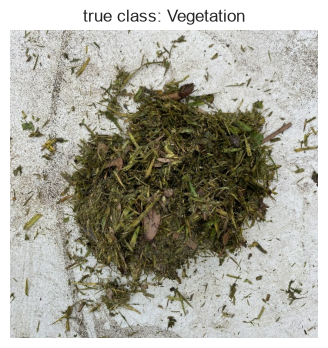

[OK] request 32180145 | input: image | 0.26s
Category: Vegetation (98.9%)   top-3: [('Vegetation', 0.989), ('Miscellaneous Trash', 0.002), ('Metal', 0.002)]

How to recycle Vegetation:
1. Accepted: Grass clippings; Leaves and small branches; Flowers and plants; Garden trimmings; Weeds (non-invasive); Tree prunings
2. Not accepted: Soil or dirt; Rocks or gravel; Treated wood; Plastic bags; Invasive plants or diseased vegetation
3. Prepare: Cut branches to appropriate length (usually under 4 feet); Remove non-plant materials; Keep separate from other waste streams
4. Where to put it: Use dedicated yard waste bins or paper yard waste bags.
5. Why it matters: Recycled vegetation becomes valuable mulch and compost for community use.
Tip: Consider home composting for small amounts.

(generation: generated, grounding 1.00)
Relevant policy documents: ['#5 Vegetation Recycling Guidelines', '#10 Municipal Waste Guidelines', '#11 Residential Recycling Rules', '#14 Community Recycling Program']




In [ ]:
# (d) A full worked example with a test image
p = sample_paths[0]
plt.figure(figsize=(4, 4))
plt.imshow(Image.open(p))
plt.axis('off')
plt.title(f"true class: {pathlib.Path(p).parent.name}")
plt.show()

example = waste_management_assistant(p, 'image'); show_result(example)

print("\n" + "=" * 90 + "\n")
example_txt = waste_management_assistant("empty aluminium tin with a bit of food residue", 'text'); show_result(example_txt)

In [36]:
# (e) Challenging EDGE CASES - the assistant must degrade gracefully, never crash
noise_img = np.random.randint(0, 255, (300, 200, 3)).astype('uint8')       # not a waste photo
gray_img = np.random.randint(0, 255, (224, 224)).astype('uint8')           # grayscale array
edge_cases = [
    ("missing file",               "does_not_exist.jpg",                "image"),
    ("random-noise image",         noise_img,                           "image"),
    ("grayscale array",            gray_img,                            "image"),
    ("wrong image type (int)",     42,                                  "image"),
    ("empty text",                 "   ",                               "text"),
    ("non-string text",            12345,                               "text"),
    ("gibberish text",             "asdkjh qwe zxcvb",                  "text"),
    ("typos",                      "plastik bottel wth lid",            "text"),
    ("regional term",              "rubbish from the garden: hedge cuttings", "text"),
    ("multi-material item",        "glass jar with a metal lid",        "text"),
    ("very long text",             "an old " + "very " * 80 + "worn cotton towel", "text"),
    ("bad input_type",             "banana peel",                       "video"),
]
rows = []
for name, data, typ in edge_cases:
    r = waste_management_assistant(data, typ)
    rows.append(dict(case=name, status=r['status'], category=r['category'],
                     confidence=None if r['confidence'] is None else round(r['confidence'], 2),
                     note=(r['warnings'][0][:70] if r['warnings'] else '')))
display(pd.DataFrame(rows))

,case,status,category,confidence,note
0,missing file,error,NaN,NaN,FileNotFoundError: Image not found: does_not_e...
1,random-noise image,low_confidence,Glass,0.30,Confidence 30% is below 60%; please send a des...
2,grayscale array,low_confidence,Cardboard,0.42,Confidence 42% is below 60%; please send a des...
3,wrong image type (int),error,NaN,NaN,TypeError: Unsupported image input type: int
4,empty text,error,NaN,NaN,ValueError: Description is empty
5,non-string text,error,NaN,NaN,TypeError: Text input must be a string
6,gibberish text,low_confidence,Textile Trash,0.29,"None of the words were recognised, so this gue..."
7,typos,ok,Plastic,0.93,Few words were recognised; try describing the ...
8,regional term,ok,Vegetation,1.00,
9,multi-material item,ok,Glass,0.59,


In [37]:
# (f) User feedback loop demonstration
r1 = waste_management_assistant("AA batteries", 'text')
submit_feedback(r1, correct_category='Miscellaneous Trash', helpful=True, comment="correct, thanks")
r2 = waste_management_assistant("torn industrial purple plastic rug partially filled", 'text')
submit_feedback(r2, correct_category='Textile Trash', helpful=False, comment="it is a rug")
print(feedback_report())
# In production, `retraining_rows` (plus the raw descriptions) are appended to the training set at each retrain,
# and a rising share of low-confidence / unhelpful results would trigger a model review.

{'n_feedback': 2, 'accuracy_from_feedback': np.float64(0.5), 'retraining_rows':   input_type predicted correct_category
1       text   Plastic    Textile Trash}


### 5.4 Using the assistant outside the notebook

All trained artefacts are saved under `Models/` and cached under `Data/cache/`, so the assistant works from any script or a fresh kernel without re-training:

```python
from Pipeline.assistant import EcoSortAssistant, show_result
bot = EcoSortAssistant()                         # loads Models/ecosort_cnn_final.keras, text_model.joblib, instruction_cache.json
show_result(bot("Data/RealWaste/.../Glass/Glass_12.jpg", "image"))
show_result(bot("empty tin of beans", "text"))
```



### 5.4 Summary, Design Justification and Limitations

**What was built**

* **CNN:** MobileNetV2 transfer learning with augmentation, class weights, a hyper-parameter search for the head, and staged fine-tuning. Evaluated with accuracy, per-class report, confusion matrix, most-confused pairs and a gallery of confident mistakes.
* **Text classifier:** TF-IDF word+character n-grams with four classical models compared (plus a sentence-embedding variant), tuned with 5-fold CV, evaluated once on a held-out test set with error analysis and out-of-distribution sanity checks. Duplicates were removed *before* splitting to avoid leakage.
* **RAG:** section-level policy chunks + CSV disposal knowledge, MiniLM embeddings and exact cosine retrieval, tuned retrieval weight, `flan-t5-base` fine-tuned on retrieval-grounded targets, decoding strategies compared, and a **grounding check with extractive fallback**.
* **Assistant:** one entry point for image or text, structured result schema, confidence thresholds chosen from validation data, input validation and error handling, caching, and a feedback loop.

**Findings about the provided data that affect the design**

1. The bundled programme documents contradict the category-specific ones (plastic bags/film, window glass/mirrors) *and* have later dates, so "latest document wins" would give residents wrong advice. The system treats category-specific documents as authoritative, flags the conflict in the returned policy documents, and recommends that Metro City resolve it.
2. The starter pipeline shuffled the validation set and then split it with `take`/`skip`, which leaks images between validation and test. `Pipeline/images.py` now makes a stratified, deterministic 80/10/10 split by image (every class in every split) and caches the decoded arrays.
3. The brief describes `waste_policy_documents.csv` and 8 image classes; the provided files are JSON and the dataset has 9 classes.

**Limitations and next steps**

* RealWaste photos share one background and camera; resident phone photos will differ. Collect real uploads (via the feedback loop) and add stronger augmentation or a larger backbone (EfficientNet).
* The text data is template-generated, so its scores overstate real-world accuracy; real resident text should be collected and labelled.
* Only 9 categories mean generation targets are structurally similar; the fine-tuned generator is best seen as a policy-grounded formatter. The grounding check measures word-level support, not logical correctness, so a human review of the policy source documents remains necessary.
* Classification is per item: a resident who has an item made of several materials (e.g. a glass jar with a metal lid) is told one category. A multi-label model would be a natural extension.